In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import matplotlib
import pydotplus

from sklearn import preprocessing
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
# from scipy.stats import loguniform
from xgboost import XGBClassifier
from seaborn import boxplot

from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn import model_selection
from sklearn.model_selection import RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
from sklearn import tree

import warnings 
warnings.filterwarnings('ignore')

matplotlib.style.use('ggplot')

In [2]:
df = pd.read_csv('Gangguan_Tidur.csv')
df.head()
df.tail()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
373,374,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [4]:
df['Sleep Disorder'].fillna('None', inplace=True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


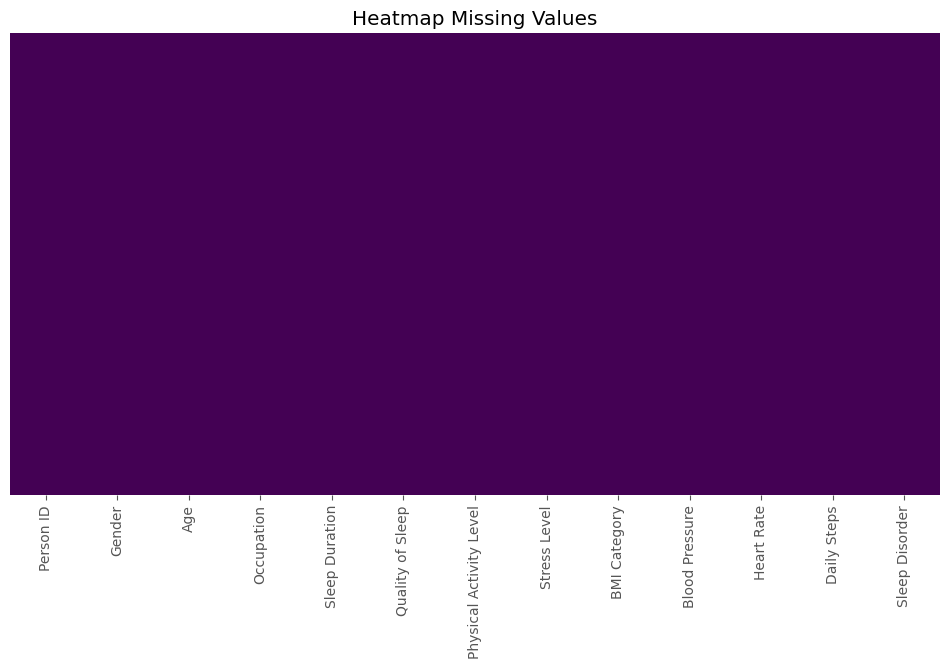

In [6]:
#heatmap missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap Missing Values')
plt.show()

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df=df.drop(columns='Person ID')
df['Blood Pressure']=df['Blood Pressure'].apply(lambda x:'Normal' if x in ['120/80','126/83','125/80','128/84','129/84','117/76','118/76','115/75','125/82','122/80'] else 'Abnormal')
# 0 = normal blood pressure
# 1 = abnormal blood pressure

In [9]:
df.describe()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [10]:
df.describe(include='O')

,Gender,Occupation,BMI Category,Blood Pressure,Sleep Disorder
count,374,374,374,374,374
unique,2,11,4,2,3
top,Male,Nurse,Normal,Abnormal,None
freq,189,73,195,218,219


In [11]:
# df_num = df.select_dtypes('number')

# # Select columns with object (string) data
# string_coll = df.select_dtypes(include='object').columns

# # Convert categorical string columns to integer codes
# for col in string_coll:
#     df_num[col] = df[col].astype('category').cat.codes

# # Combine the converted categorical columns with the numeric DataFrame
# df_num.info()

In [12]:
# df_num.describe()

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Sleep Duration'}>,
        <Axes: title={'center': 'Quality of Sleep'}>],
       [<Axes: title={'center': 'Physical Activity Level'}>,
        <Axes: title={'center': 'Stress Level'}>,
        <Axes: title={'center': 'Heart Rate'}>],
       [<Axes: title={'center': 'Daily Steps'}>, <Axes: >, <Axes: >]],
      dtype=object)

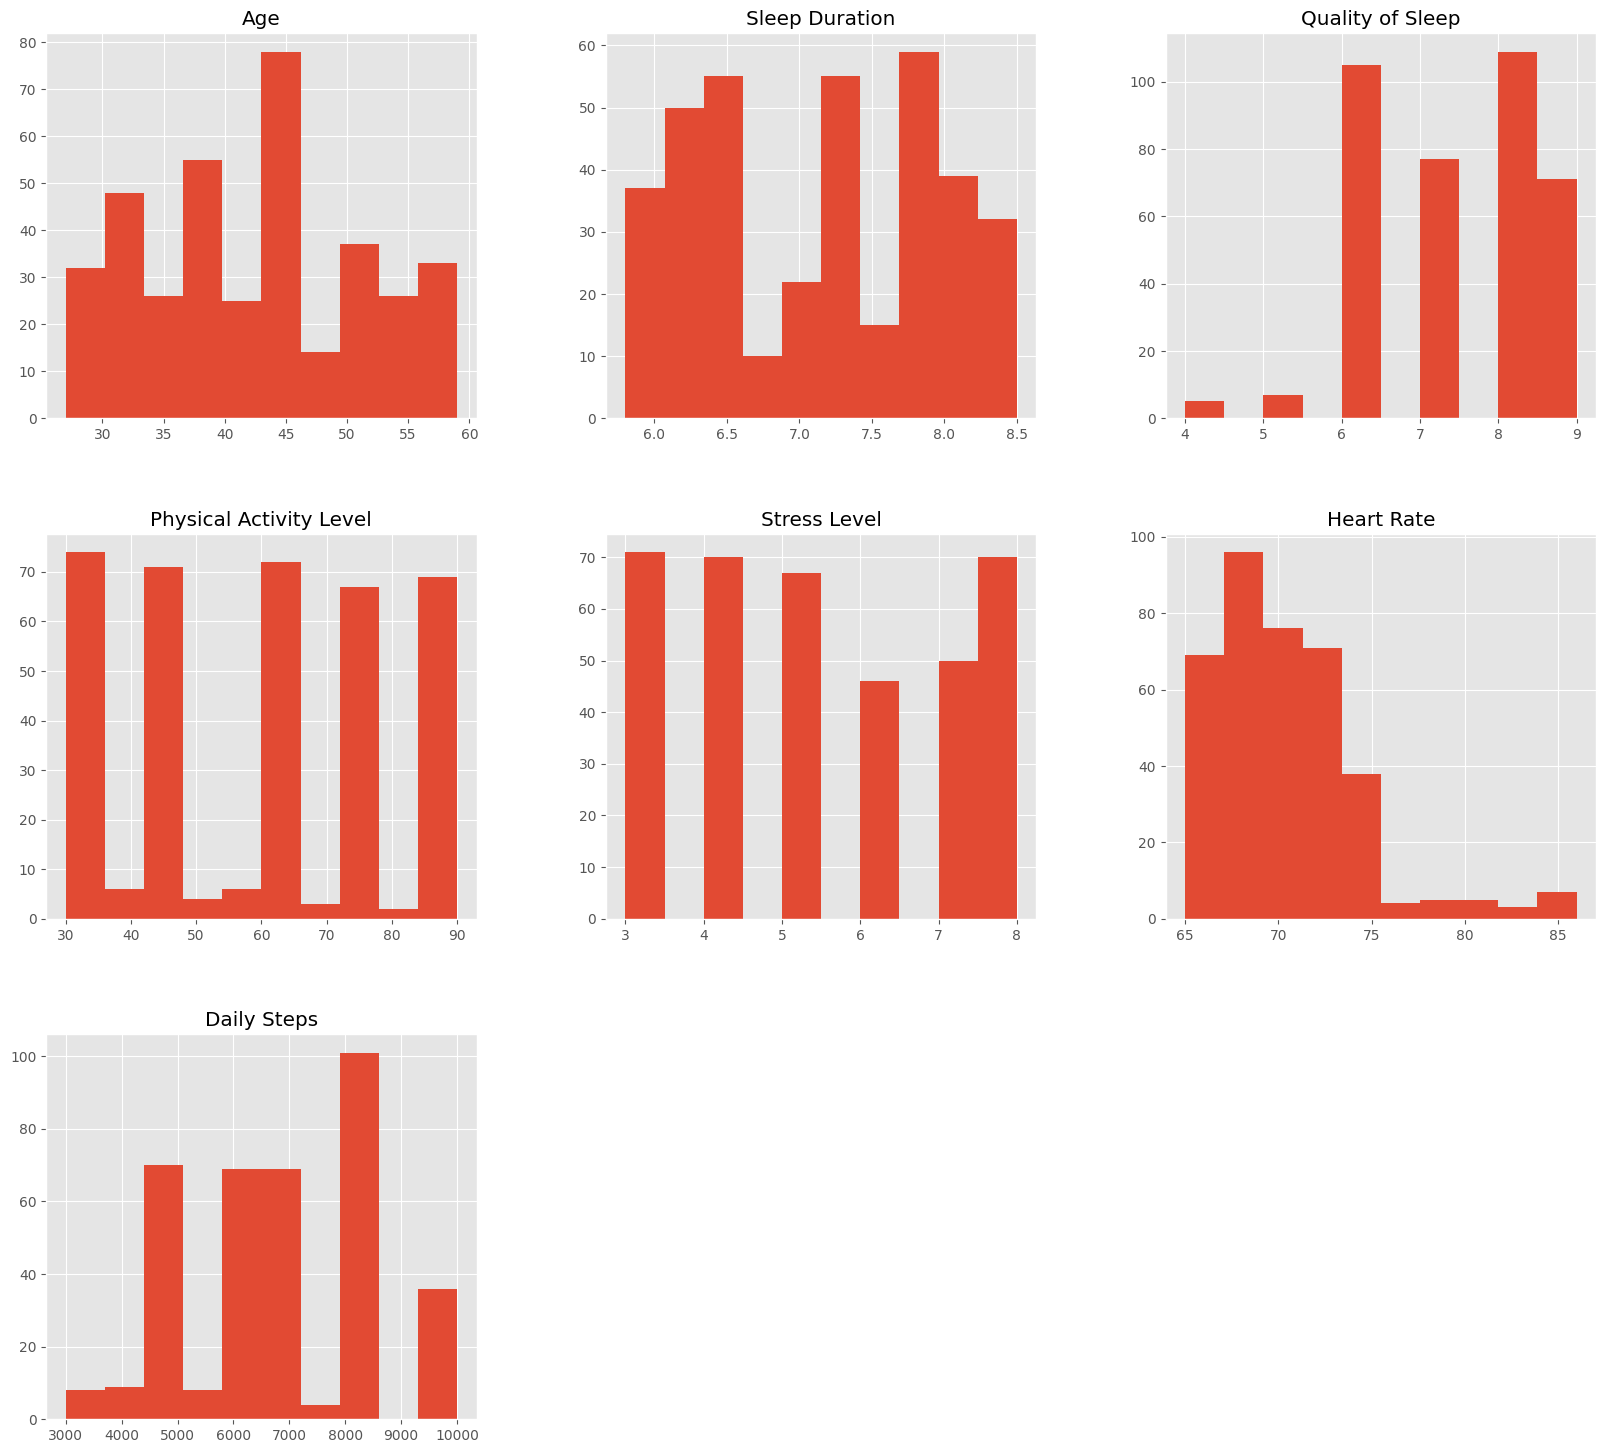

In [13]:
df.hist(figsize=[20,18],bins=10)

In [14]:
df.dtypes

Gender                      object
Age                          int64
Occupation                  object
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                object
Blood Pressure              object
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder              object
dtype: object

In [15]:
def remove_outliers_multiple_columns(df, group_col, target_cols):
    df_clean = pd.DataFrame()

    for group in df[group_col].unique():
        group_df = df[df[group_col] == group].copy()

        for col in target_cols:
            if pd.api.types.is_numeric_dtype(group_df[col]):
                Q1 = group_df[col].quantile(0.25)
                Q3 = group_df[col].quantile(0.75)
                IQR = Q3 - Q1
                lower_bound = Q1 - 1.5 * IQR
                upper_bound = Q3 + 1.5 * IQR

                group_df = group_df[(group_df[col] >= lower_bound) & (group_df[col] <= upper_bound)]
        
        df_clean = pd.concat([df_clean, group_df], ignore_index=True)

    return df_clean
target_columns = [
    "Age",
    "Sleep Duration", 
    "Quality of Sleep",
    "Physical Activity Level", 
    "Stress Level",
    "Heart Rate", 
    "Daily Steps"
]

df_clean = remove_outliers_multiple_columns(df, group_col='Sleep Disorder', target_cols=target_columns)

In [16]:
target_columns = [
    "Age",
    "Sleep Duration", 
    "Quality of Sleep",
    "Physical Activity Level", 
    "Stress Level",
    "Heart Rate", 
    "Daily Steps"
]

df_clean = remove_outliers_multiple_columns(df, group_col='Sleep Disorder', target_cols=target_columns)

In [17]:
df_clean.describe()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,43.146104,7.264610,7.538961,61.987013,5.074675,69.185065,7063.961039
std,8.465378,0.764447,1.083685,20.055132,1.696214,3.081124,1452.606292
min,29.000000,5.900000,6.000000,30.000000,3.000000,65.000000,3300.000000
25%,37.000000,6.500000,7.000000,45.000000,4.000000,68.000000,6000.000000
50%,43.000000,7.250000,8.000000,60.000000,5.000000,68.000000,7000.000000
75%,50.000000,7.800000,8.000000,75.000000,6.000000,72.000000,8000.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,84.000000,10000.000000


In [18]:
fig=px.treemap(df_clean,
               path=[px.Constant('Pekerjaan'), 'Sleep Disorder', 'Occupation'],
               )
fig.show()

In [19]:
#def remove_outliers_iqr_grouped(df, group_col, target_col):
#    frames = []

#    for group in df[group_col].unique():
#        group_df = df[df[group_col] == group].copy()
#        Q1 = group_df[target_col].quantile(0.25)
#        Q3 = group_df[target_col].quantile(0.75)
#        IQR = Q3 - Q1

#        lower = Q1 - 1.5 * IQR
#        upper = Q3 + 1.5 * IQR

#        filtered_df = group_df[(group_df[target_col] >= lower) & (group_df[target_col] <= upper)]
#        frames.append(filtered_df)

#    return pd.concat(frames, ignore_index=True)

In [20]:
#df_clean = remove_outliers_iqr_grouped(df, group_col='Sleep Disorder', target_col='Age')

In [21]:
fig = px.box(df,
             x='Sleep Disorder',
             y='Age',
             notched=True)
fig.show()

In [22]:
fig = px.box(df_clean,
             x='Sleep Disorder',
             y='Age',
             notched=True)
fig.show()

In [23]:
# for cat in df_clean['Sleep Disorder'].unique():
#     ages = df_clean[df_clean['Sleep Disorder'] == cat]['Age']
#     Q1 = ages.quantile(0.25)
#     Q3 = ages.quantile(0.75)
#     IQR = Q3 - Q1
#     lower = Q1 - 1.5 * IQR
#     upper = Q3 + 1.5 * IQR
#     outliers = ages[(ages < lower) | (ages > upper)]
#     print(f"{cat}: {len(outliers)} outliers")

In [24]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Sleep Duration',
             #color='Gender',
             notched=True)
fig.show()

In [25]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Sleep Duration',
             #color='Gender',
             notched=True)
fig.show()

In [26]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Quality of Sleep',
             #color='Gender',
             notched=True)
fig.show()

In [27]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Quality of Sleep',
             #color='Gender',
             notched=True)
fig.show()

In [28]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Physical Activity Level',
             #color='Gender',
             notched=True)
fig.show()

In [29]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Physical Activity Level',
             #color='Gender',
             notched=True)
fig.show()

In [30]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Stress Level',
             #color='Gender',
             notched=True)
fig.show()

In [31]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Stress Level',
             #color='Gender',
             notched=True)
fig.show()

In [32]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Heart Rate',
             #color='Gender',
             notched=True)
fig.show()

In [33]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Heart Rate',
             #color='Gender',
             notched=True)
fig.show()

In [34]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Daily Steps',
             #color='Gender',
             notched=True)
fig.show()

In [35]:
fig= px.box(df_clean,
             x='Sleep Disorder',
             y='Daily Steps',
             #color='Gender',
             notched=True)
fig.show()

In [36]:
df_clean.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,Male,29,Doctor,7.8,7,75,6,Normal,Normal,70,8000,None
1,Male,29,Doctor,7.8,7,75,6,Normal,Normal,70,8000,None
2,Male,29,Doctor,7.8,7,75,6,Normal,Normal,70,8000,None
3,Male,29,Doctor,6.1,6,30,8,Normal,Normal,70,8000,None
4,Male,29,Doctor,7.8,7,75,6,Normal,Normal,70,8000,None


In [37]:
df_clean.tail()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
303,Female,45,Teacher,6.6,7,45,4,Overweight,Abnormal,65,6000,Insomnia
304,Female,45,Teacher,6.6,7,45,4,Overweight,Abnormal,65,6000,Insomnia
305,Female,45,Teacher,6.6,7,45,4,Overweight,Abnormal,65,6000,Insomnia
306,Female,45,Teacher,6.6,7,45,4,Overweight,Abnormal,65,6000,Insomnia
307,Female,45,Teacher,6.6,7,45,4,Overweight,Abnormal,65,6000,Insomnia


In [38]:
# df=df_clean

In [39]:
fig=px.histogram(df,
                 x=df['Age'],
                 hover_data=df.columns,
                 title='Distribusi Umur')
fig.show()

In [40]:
print(df['Age'].value_counts())

Age
43    34
44    30
37    20
38    20
50    20
31    18
32    17
53    17
59    16
39    15
45    14
33    13
29    13
30    13
36    12
35    12
41    12
49    11
42     9
57     9
52     9
51     8
54     7
58     6
28     5
40     4
48     3
55     2
34     2
56     2
27     1
Name: count, dtype: int64


In [41]:
fig=px.histogram(df,
                 x=df['Sleep Duration'],
                 hover_data=df.columns,
                 title='Distribusi Durasi Tidur')
fig.show()

In [42]:
print(df['Sleep Duration'].value_counts())

Sleep Duration
7.2    36
6.0    31
7.8    28
6.5    26
6.1    25
7.7    24
6.6    20
7.1    19
8.1    15
7.3    14
8.4    14
8.0    13
6.3    13
8.5    13
6.2    12
8.2    11
7.6    10
6.4     9
7.9     7
8.3     5
7.4     5
6.7     5
7.5     5
6.8     5
5.9     4
6.9     3
5.8     2
Name: count, dtype: int64


In [43]:
fig=px.histogram(df,
                 x=df['Quality of Sleep'],
                 hover_data=df.columns,
                 title='Distribusi Kualitas Tidur')
fig.show()

In [44]:
print(df['Quality of Sleep'].value_counts())

Quality of Sleep
8    109
6    105
7     77
9     71
5      7
4      5
Name: count, dtype: int64


In [45]:
fig=px.histogram(df,
                 x=df['Physical Activity Level'],
                 hover_data=df.columns,
                 title='Distribusi Aktifitas Fisik')
fig.show()

In [46]:
print(df['Physical Activity Level'].value_counts())

Physical Activity Level
60    70
30    68
45    68
75    67
90    67
40     6
55     6
35     4
50     4
70     3
42     2
32     2
80     2
65     2
85     2
47     1
Name: count, dtype: int64


In [47]:
print(df['Stress Level'].value_counts())

Stress Level
3    71
8    70
4    70
5    67
7    50
6    46
Name: count, dtype: int64


In [48]:
fig=px.histogram(df,
                 x=df['Stress Level'],
                 hover_data=df.columns,
                 title='Distribusi Stress level')
fig.show()

In [49]:
print(df['Heart Rate'].value_counts())

Heart Rate
68    94
70    76
72    69
65    67
75    36
78     5
85     3
80     3
77     2
76     2
69     2
67     2
81     2
84     2
74     2
83     2
73     2
86     2
82     1
Name: count, dtype: int64


In [50]:
fig=px.histogram(df,
                 x=df['Heart Rate'],
                 hover_data=df.columns,
                 title='Distribusi Denyut Jantung')
fig.show()

In [51]:
print(df['Daily Steps'].value_counts())

Daily Steps
8000     101
5000      68
6000      68
7000      66
10000     36
5500       4
3000       3
3500       3
6800       3
4000       3
4200       2
4100       2
5200       2
5600       2
4800       2
3300       2
7500       2
7300       2
3700       2
6200       1
Name: count, dtype: int64


In [52]:
fig=px.histogram(df,
                 x=df['Daily Steps'],
                 hover_data=df.columns,
                 title='Distribusi Jumlah Langkah Perhari')
fig.show()

In [53]:
fig=px.histogram(df,
                 x=df['Gender'],
                 hover_data=df.columns,
                 title='Distribusi Gender')
fig.show()

In [54]:
fig=px.histogram(df,
                 x=df['Occupation'],
                 hover_data=df.columns,
                 title='Distribusi Pekerjaan')
fig.show()

In [55]:
fig=px.histogram(df,
                 x=df['BMI Category'],
                 hover_data=df.columns,
                 title='Distribusi Berat Badan')
fig.show()

In [56]:
fig=px.histogram(df,
                 x=df['Blood Pressure'],
                 hover_data=df.columns,
                 title='Distribusi Tekanan Darah')
fig.show()

In [57]:
fig=px.histogram(df,
                 x=df['Sleep Disorder'],
                 hover_data=df.columns,
                 title='Distribusi Penyakit tidur')
fig.show()

In [58]:
print(df['Sleep Disorder'].value_counts())

Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


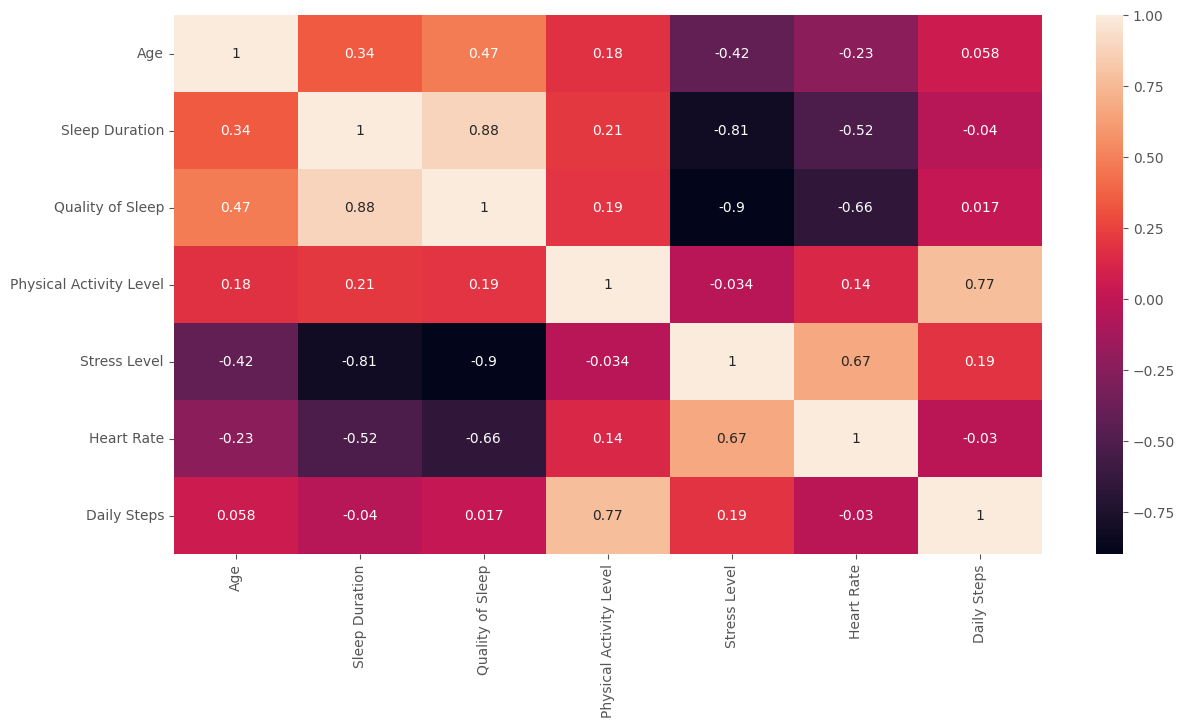

In [59]:
plt.figure(figsize=[14,7])
sns.heatmap(df.select_dtypes('number').corr(),annot=True)
plt.show()

In [60]:
print(df.nunique())

Gender                      2
Age                        31
Occupation                 11
Sleep Duration             27
Quality of Sleep            6
Physical Activity Level    16
Stress Level                6
BMI Category                4
Blood Pressure              2
Heart Rate                 19
Daily Steps                20
Sleep Disorder              3
dtype: int64


In [61]:
df['Gender'].value_counts()

Gender
Male      189
Female    185
Name: count, dtype: int64

In [62]:
fig=px.histogram(df,
                 x=df['Gender'],
                 hover_data=df.columns,
                 title='Distribusi gender')
fig.show()

In [63]:
df.groupby('Gender')['Sleep Disorder'].value_counts()

Gender  Sleep Disorder
Female  None               82
        Sleep Apnea        67
        Insomnia           36
Male    None              137
        Insomnia           41
        Sleep Apnea        11
Name: count, dtype: int64

In [64]:
fig=px.histogram(df,
                 x='Gender',
                 color='Sleep Disorder',
                 hover_data=df.columns,
                 title='Distribusi gangguan tidur berdasarkan gender',
                 barmode='group')
fig.show()

In [65]:
print(df['Blood Pressure'].value_counts())
print(df.groupby('Sleep Disorder')['Blood Pressure'].value_counts())

Blood Pressure
Abnormal    218
Normal      156
Name: count, dtype: int64
Sleep Disorder  Blood Pressure
Insomnia        Abnormal           73
                Normal              4
None            Normal            148
                Abnormal           71
Sleep Apnea     Abnormal           74
                Normal              4
Name: count, dtype: int64


In [66]:
fig=px.sunburst(df,path=[px.Constant('Tekanan Darah'),'Sleep Disorder','Blood Pressure']
                 )
fig.show()

In [67]:
df['BMI Category'].replace({'Normal Weight': 'Under Weight'}, inplace=True)

In [68]:
print(df['BMI Category'].value_counts())
print(df.groupby('Sleep Disorder')['BMI Category'].value_counts())

BMI Category
Normal          195
Overweight      148
Under Weight     21
Obese            10
Name: count, dtype: int64
Sleep Disorder  BMI Category
Insomnia        Overweight       64
                Normal            7
                Obese             4
                Under Weight      2
None            Normal          183
                Overweight       19
                Under Weight     17
Sleep Apnea     Overweight       65
                Obese             6
                Normal            5
                Under Weight      2
Name: count, dtype: int64


In [69]:
fig=px.sunburst(df_clean,
                path=[px.Constant('BMI'),'Sleep Disorder', 'BMI Category'],
                )
fig.show()

In [70]:
fig=px.sunburst(df,
                path=[px.Constant('BMI'),'Sleep Disorder', 'BMI Category'],
                )
fig.show()

In [71]:
print(df['Occupation'].value_counts())
print(df.groupby('Occupation')['Sleep Disorder'].value_counts())

Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64
Occupation            Sleep Disorder
Accountant            None              30
                      Insomnia           7
Doctor                None              64
                      Sleep Apnea        4
                      Insomnia           3
Engineer              None              57
                      Insomnia           5
                      Sleep Apnea        1
Lawyer                None              42
                      Sleep Apnea        3
                      Insomnia           2
Manager               None               1
Nurse                 Sleep Apnea       61
                      None               9
                      Insom

In [72]:
fig=px.treemap(df_clean,
               path=[px.Constant('Pekerjaan'), 'Sleep Disorder', 'Occupation'],
               )
fig.show()

In [73]:
fig=px.treemap(df,
               path=[px.Constant('Pekerjaan'), 'Sleep Disorder', 'Occupation'],
               )
fig.show()

In [74]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Age',
             #color='Gender',
             notched=True)
fig.show()

In [75]:
print(df.groupby(['Sleep Disorder'])['Sleep Duration'].value_counts())

Sleep Disorder  Sleep Duration
Insomnia        6.5               23
                6.6               17
                6.3               13
                6.4                7
                6.7                3
                6.8                3
                7.2                2
                7.3                2
                7.8                2
                5.9                1
                6.0                1
                6.1                1
                7.6                1
                8.3                1
None            7.2               33
                7.8               25
                7.7               23
                7.1               18
                6.0               17
                8.4               14
                8.5               13
                7.3               12
                6.1               11
                6.2                9
                7.6                9
                7.9                7
       

In [76]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Sleep Duration',
             #color='Gender'
             )
fig.show()

In [77]:
print(df.groupby(['Sleep Disorder'])['Quality of Sleep'].value_counts())

Sleep Disorder  Quality of Sleep
Insomnia        7                    34
                6                    32
                8                     5
                5                     4
                4                     1
                9                     1
None            8                   101
                6                    40
                7                    40
                9                    38
Sleep Apnea     6                    33
                9                    32
                4                     4
                5                     3
                7                     3
                8                     3
Name: count, dtype: int64


In [78]:
fig = px.box(df,
             x='Sleep Disorder',
             y='Quality of Sleep',
             notched=True)
fig.show()

In [79]:
print(df.groupby(['Sleep Disorder'])['Physical Activity Level'].value_counts())

Sleep Disorder  Physical Activity Level
Insomnia        45                         59
                30                          5
                90                          4
                40                          3
                35                          2
                60                          2
                65                          2
None            60                         64
                30                         60
                75                         36
                90                         33
                45                          6
                55                          6
                50                          4
                70                          3
                40                          2
                42                          2
                80                          2
                47                          1
Sleep Apnea     75                         31
                90                      

In [80]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Physical Activity Level',
             #color='Gender',
             notched=True)
fig.show()

In [81]:
print(df.groupby(['Sleep Disorder'])['Stress Level'].value_counts())

Sleep Disorder  Stress Level
Insomnia        7               41
                4               24
                5                6
                8                3
                6                2
                3                1
None            5               57
                4               43
                6               43
                3               40
                8               33
                7                3
Sleep Apnea     8               34
                3               30
                7                6
                5                4
                4                3
                6                1
Name: count, dtype: int64


In [82]:
fig= px.sunburst(df,path=[px.Constant('Stress Level'),'Sleep Disorder', 'Stress Level'])
fig.show()

In [83]:
print(df.groupby(['Sleep Disorder'])['Heart Rate'].value_counts())

Sleep Disorder  Heart Rate
Insomnia        72            36
                65            26
                70             3
                68             2
                78             2
                80             2
                83             2
                74             1
                75             1
                82             1
                85             1
None            70            70
                68            62
                65            41
                72            30
                75             6
                67             2
                69             2
                73             2
                76             2
                77             2
Sleep Apnea     68            30
                75            29
                70             3
                72             3
                78             3
                81             2
                84             2
                85             2
                

In [84]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Heart Rate')
fig.show()

In [85]:
print(df.groupby(['Sleep Disorder'])['Daily Steps'].value_counts())

Sleep Disorder  Daily Steps
Insomnia        6000           60
                8000            4
                3500            3
                5000            3
                4000            2
                3000            1
                4100            1
                4800            1
                7000            1
                10000           1
None            8000           93
                5000           61
                7000           36
                6000            7
                10000           6
                5500            4
                6800            3
                4200            2
                5600            2
                7300            2
                7500            2
                6200            1
Sleep Apnea     7000           29
                10000          29
                5000            4
                8000            4
                3000            2
                3300            2
                3700

In [86]:
fig= px.box(df,
             x='Sleep Disorder',
             y='Daily Steps',
             #color='Gender',
             notched=True)
fig.show()

[]

<Figure size 1500x1000 with 0 Axes>

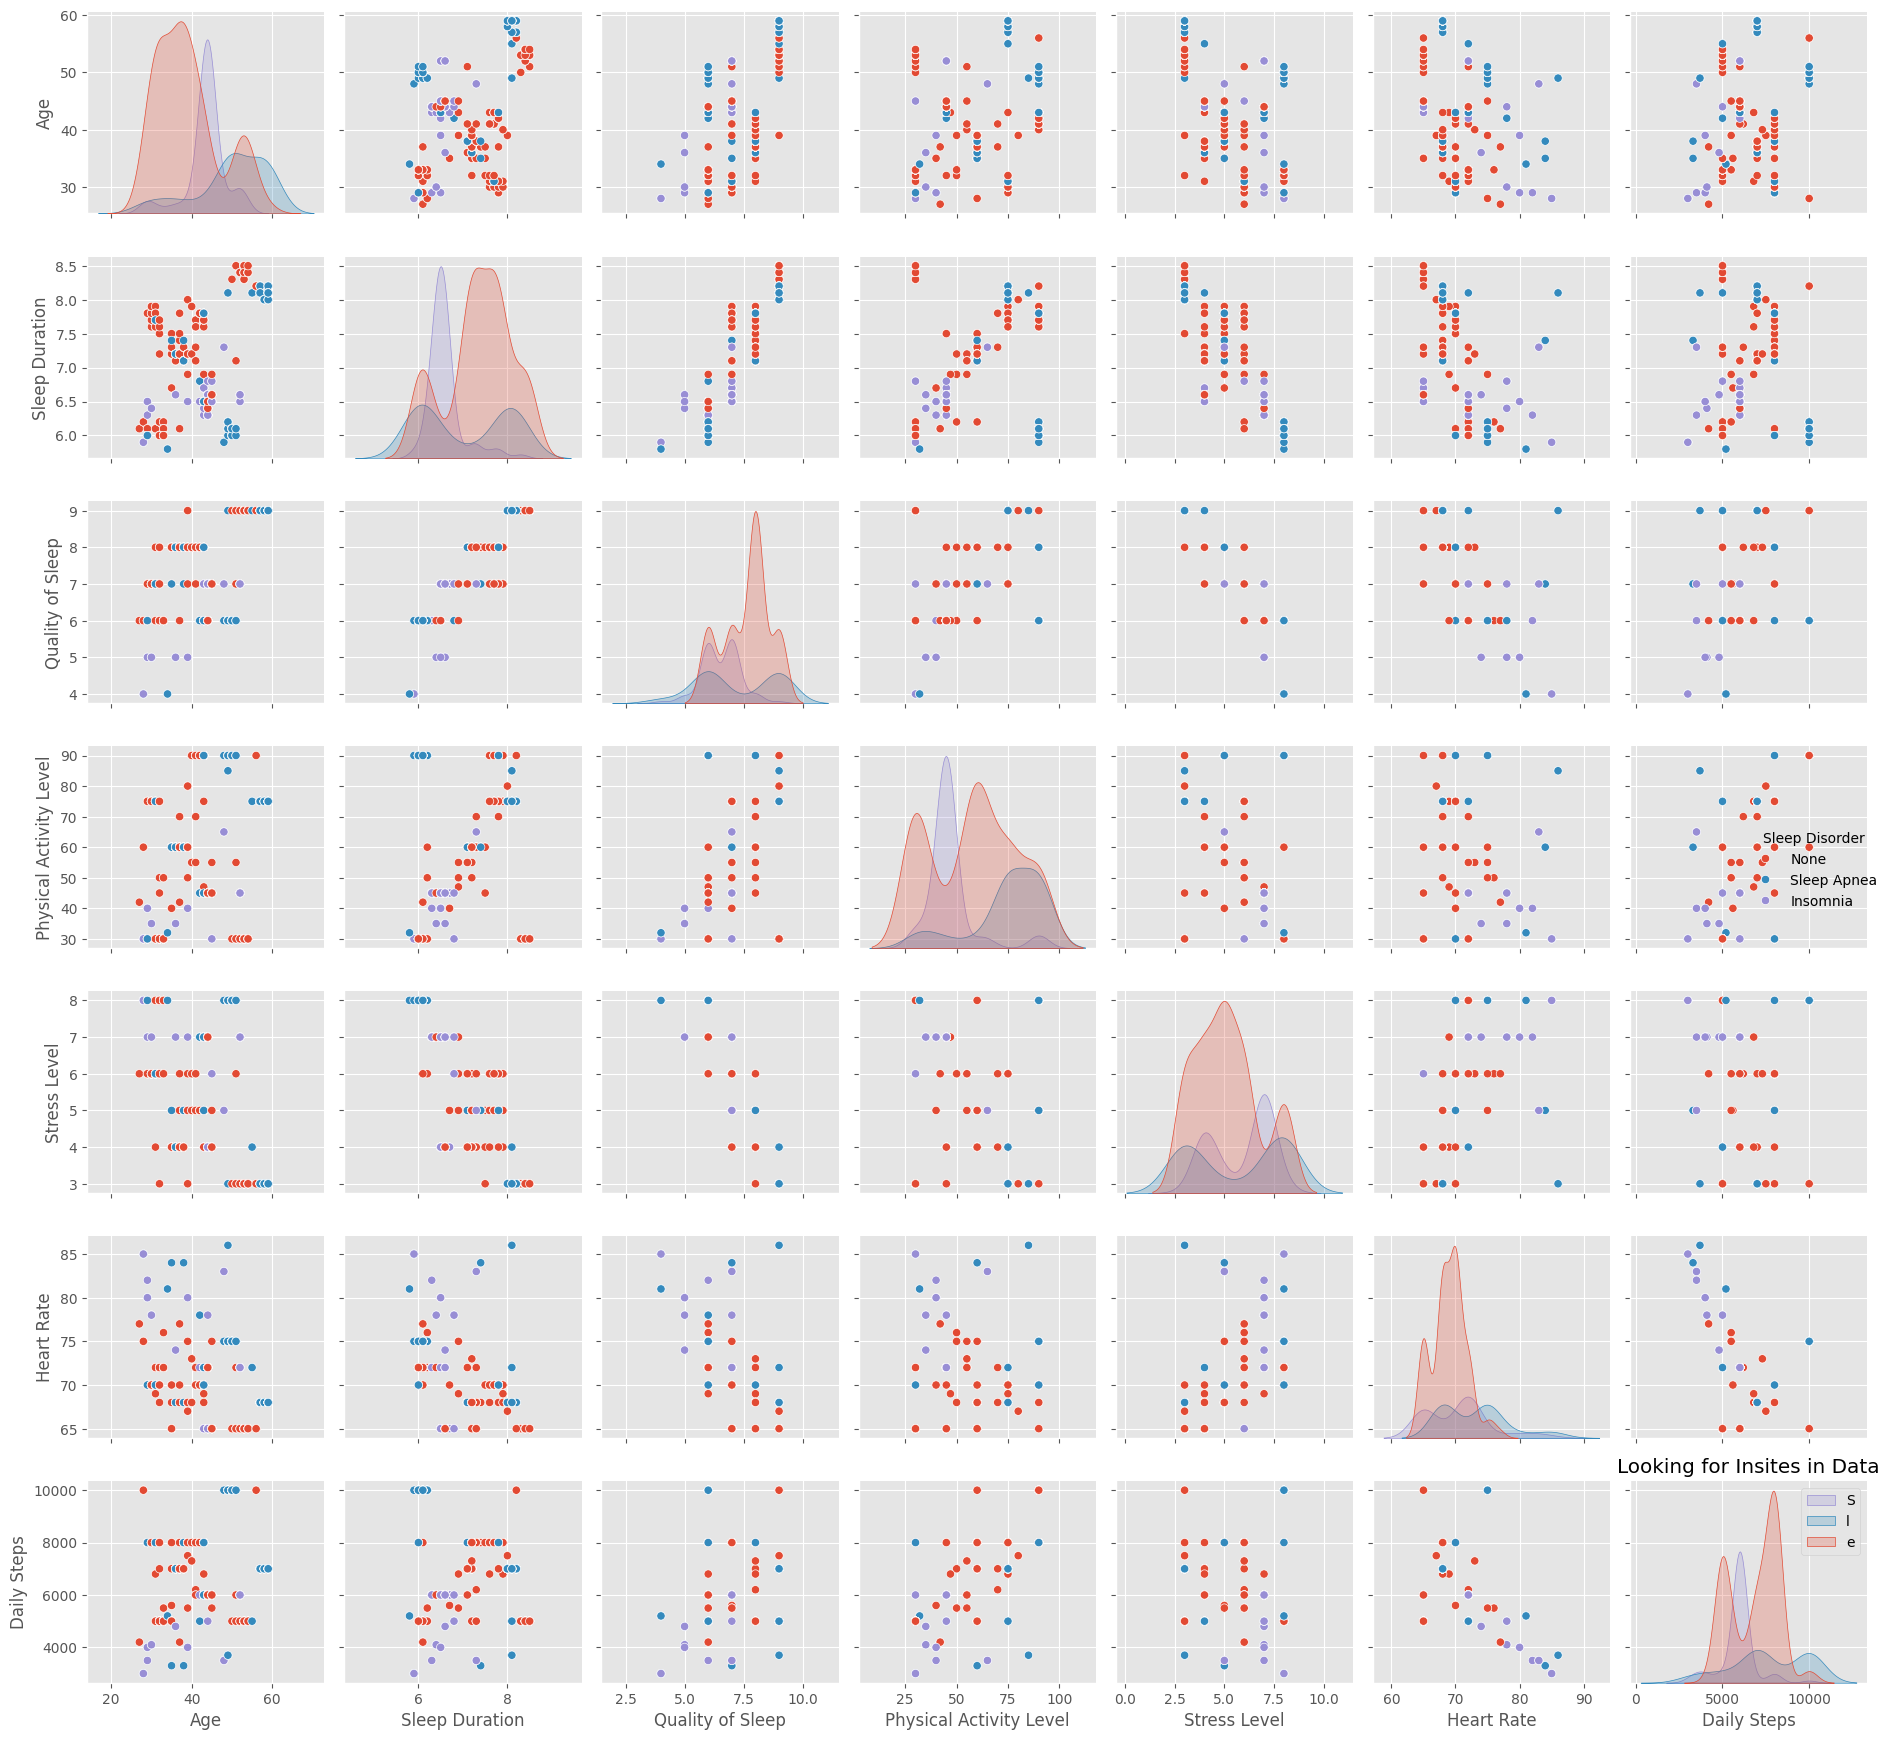

In [87]:
plt.figure(figsize=(15,10))
sns.pairplot(df,hue="Sleep Disorder")
plt.title("Looking for Insites in Data")
plt.legend("Sleep Disorder")
plt.tight_layout()
plt.plot()

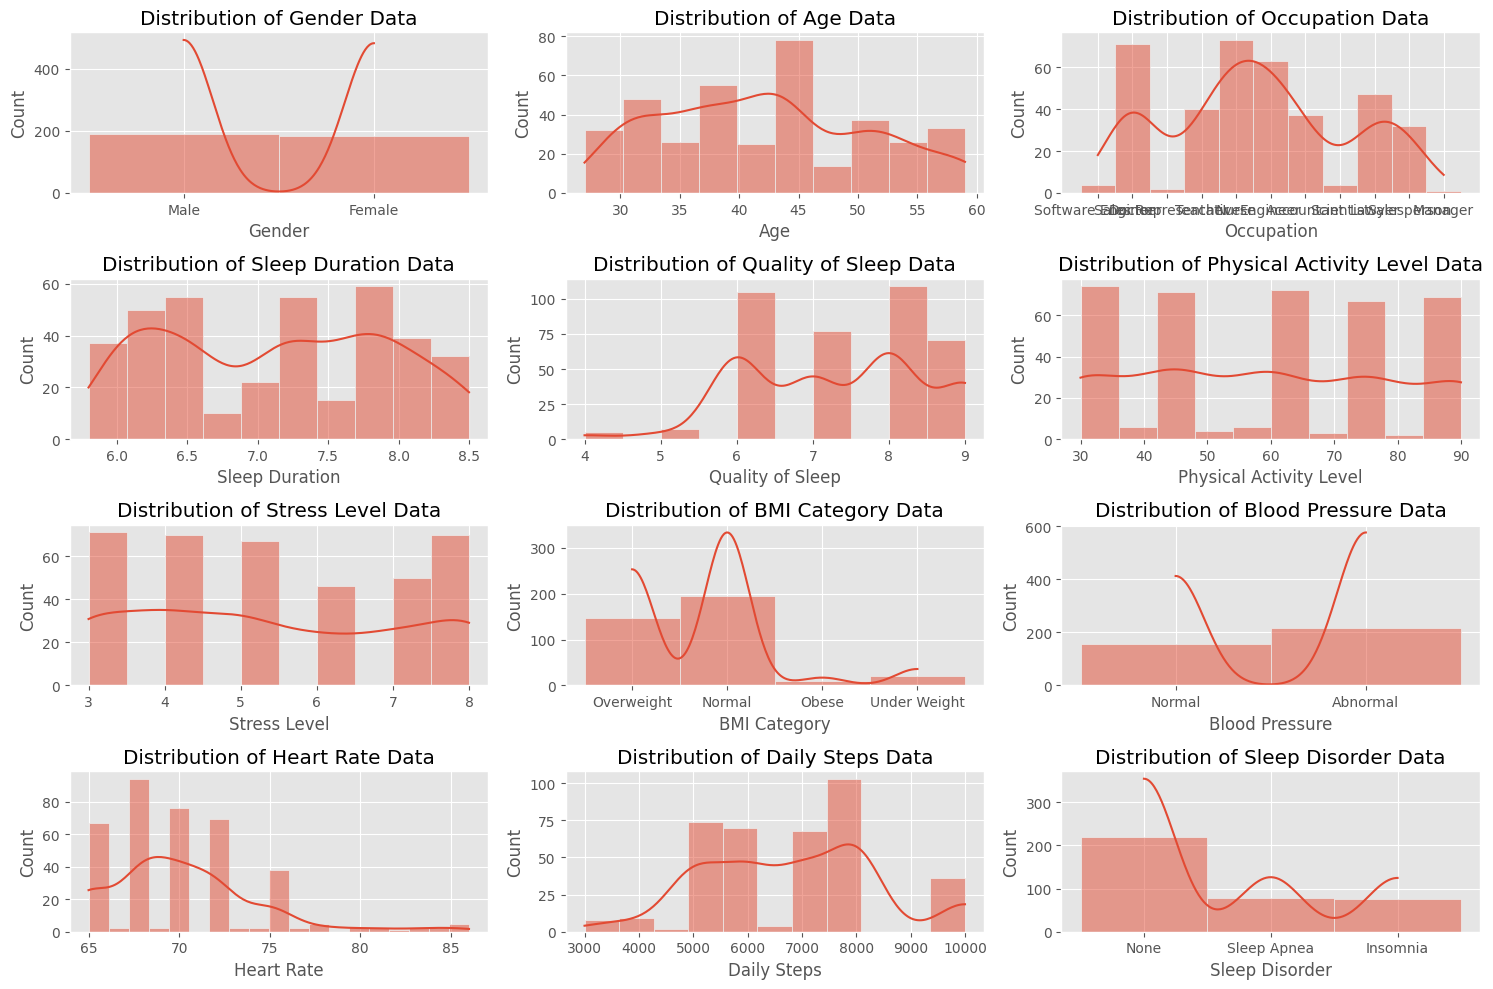

In [88]:
plt.figure(figsize=(15,10))
for i,col in enumerate(df.columns,1):
    plt.subplot(4,3,i)
    plt.title(f"Distribution of {col} Data")
    sns.histplot(df[col],kde=True)
    plt.tight_layout()
    plt.plot()

In [89]:
numeric_cols = ['Age', 'Sleep Duration', 'Quality of Sleep', 
                'Physical Activity Level', 'Stress Level', 
                'Heart Rate', 'Daily Steps']

scaler = MinMaxScaler()

# Transformasi kolom numerik
df_scaled = df.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [90]:
print(scaler.data_min_)
print(scaler.data_max_)

[  27.     5.8    4.    30.     3.    65.  3000. ]
[5.9e+01 8.5e+00 9.0e+00 9.0e+01 8.0e+00 8.6e+01 1.0e+04]


In [91]:
print("Sebelum normalisasi:")
print(df[numeric_cols].head())

print("\nSetelah normalisasi:")
print(df_scaled[numeric_cols].head())

Sebelum normalisasi:
   Age  Sleep Duration  Quality of Sleep  Physical Activity Level  \
0   27             6.1                 6                       42   
1   28             6.2                 6                       60   
2   28             6.2                 6                       60   
3   28             5.9                 4                       30   
4   28             5.9                 4                       30   

   Stress Level  Heart Rate  Daily Steps  
0             6          77         4200  
1             8          75        10000  
2             8          75        10000  
3             8          85         3000  
4             8          85         3000  

Setelah normalisasi:
       Age  Sleep Duration  Quality of Sleep  Physical Activity Level  \
0  0.00000        0.111111               0.4                      0.2   
1  0.03125        0.148148               0.4                      0.5   
2  0.03125        0.148148               0.4                     

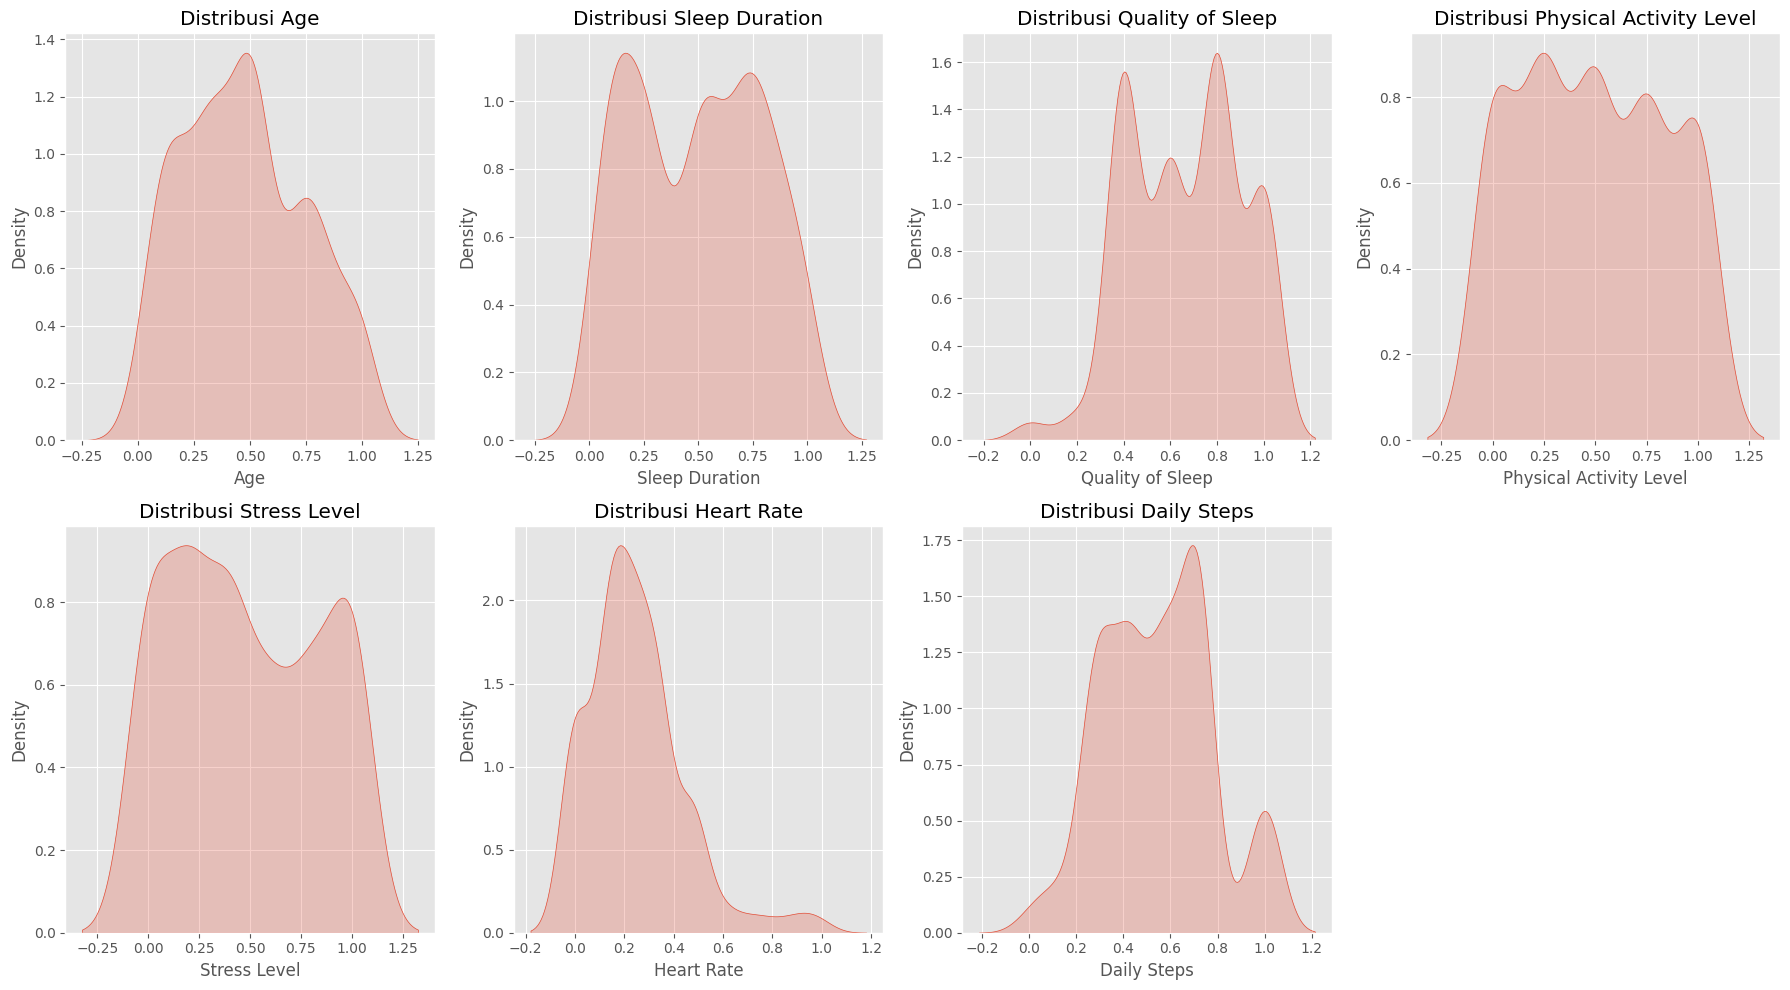

In [92]:
# Ukuran grid
rows = 2
cols = 4

# Membuat figure dan axes
fig, axes = plt.subplots(rows, cols, figsize=(18, 10))
axes = axes.flatten()  # Ubah jadi 1D agar mudah diakses dengan loop

# Loop setiap kolom dan plot KDE
for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df_scaled, x=col, fill=True, ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

# Hilangkan subplot kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

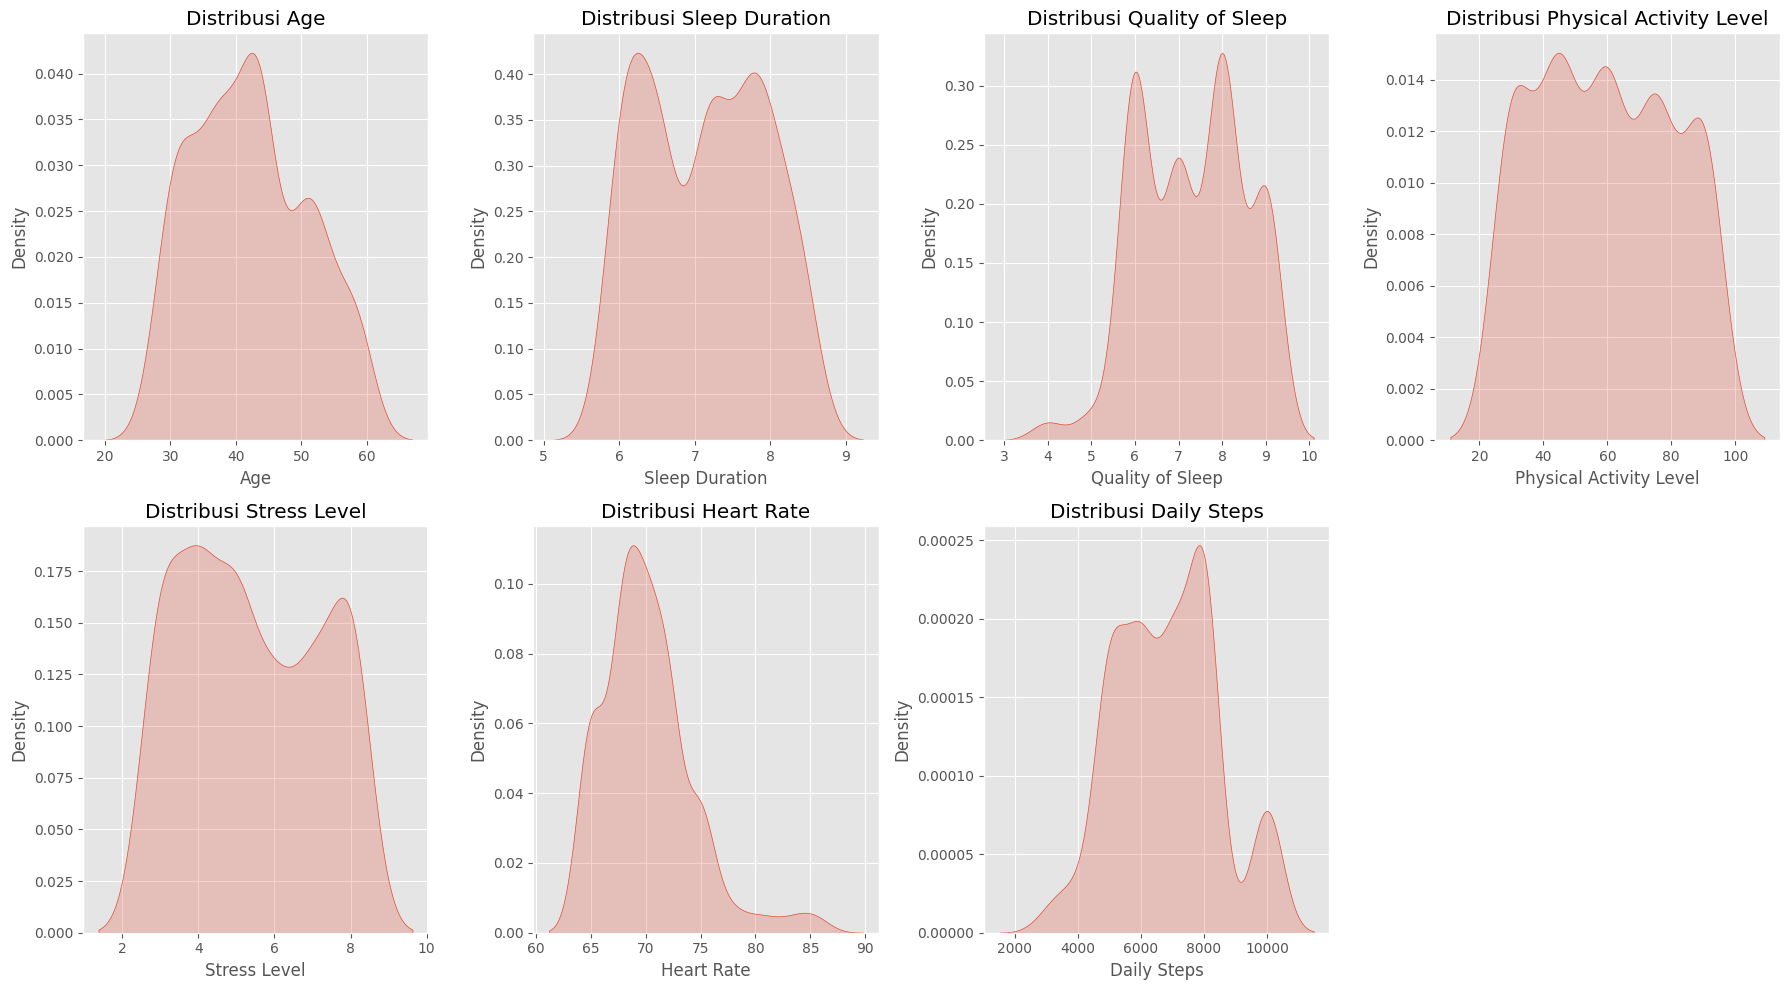

In [93]:
# Ukuran grid
rows = 2
cols = 4

# Membuat figure dan axes
fig, axes = plt.subplots(rows, cols, figsize=(18, 10))
axes = axes.flatten()  # Ubah jadi 1D agar mudah diakses dengan loop

# Loop setiap kolom dan plot KDE
for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df, x=col, fill=True, ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

# Hilangkan subplot kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

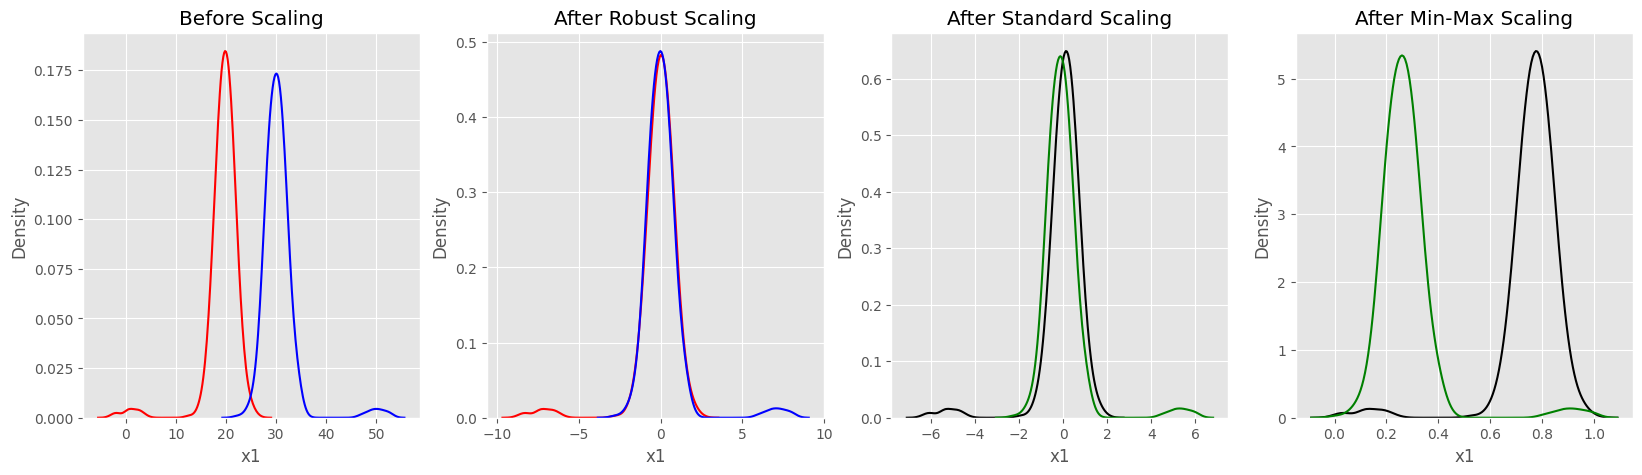

In [94]:
x = pd.DataFrame({
    # Distribution with lower outliers
    'x1': np.concatenate([np.random.normal(20, 2, 1000), np.random.normal(1, 2, 25)]),
    # Distribution with higher outliers
    'x2': np.concatenate([np.random.normal(30, 2, 1000), np.random.normal(50, 2, 25)]),
})
np.random.normal
 
scaler = preprocessing.RobustScaler()
robust_df = scaler.fit_transform(x)
robust_df = pd.DataFrame(robust_df, columns =['x1', 'x2'])
 
scaler = preprocessing.StandardScaler()
standard_df = scaler.fit_transform(x)
standard_df = pd.DataFrame(standard_df, columns =['x1', 'x2'])
 
scaler = preprocessing.MinMaxScaler()
minmax_df = scaler.fit_transform(x)
minmax_df = pd.DataFrame(minmax_df, columns =['x1', 'x2'])
 
fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, figsize =(20, 5))
ax1.set_title('Before Scaling')
 
sns.kdeplot(x['x1'], ax = ax1, color ='r')
sns.kdeplot(x['x2'], ax = ax1, color ='b')
ax2.set_title('After Robust Scaling')
 
sns.kdeplot(robust_df['x1'], ax = ax2, color ='red')
sns.kdeplot(robust_df['x2'], ax = ax2, color ='blue')
ax3.set_title('After Standard Scaling')
 
sns.kdeplot(standard_df['x1'], ax = ax3, color ='black')
sns.kdeplot(standard_df['x2'], ax = ax3, color ='g')
ax4.set_title('After Min-Max Scaling')
 
sns.kdeplot(minmax_df['x1'], ax = ax4, color ='black')
sns.kdeplot(minmax_df['x2'], ax = ax4, color ='g')
plt.show()

In [95]:
df['Sleep Disorder'].replace({'None' : 1, 'Sleep Apnea' : 2, 'Insomnia' : 3}, inplace=True)

In [96]:
df['Sleep Disorder']= df['Sleep Disorder'].astype('category').cat.codes

In [97]:
string_col = df.select_dtypes(include='object').columns

In [98]:
print(string_col)

Index(['Gender', 'Occupation', 'BMI Category', 'Blood Pressure'], dtype='object')


In [99]:
df[string_col].head()
for col in string_col:
    print(f"The distribution of categorical valeus in the {col} is : ")
    print(df[col].value_counts())

The distribution of categorical valeus in the Gender is : 
Gender
Male      189
Female    185
Name: count, dtype: int64
The distribution of categorical valeus in the Occupation is : 
Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64
The distribution of categorical valeus in the BMI Category is : 
BMI Category
Normal          195
Overweight      148
Under Weight     21
Obese            10
Name: count, dtype: int64
The distribution of categorical valeus in the Blood Pressure is : 
Blood Pressure
Abnormal    218
Normal      156
Name: count, dtype: int64


In [100]:
for col in string_col:
    print(f"The distribution of categorical valeus in the {col} is : ")
    print(df[col].value_counts())

The distribution of categorical valeus in the Gender is : 
Gender
Male      189
Female    185
Name: count, dtype: int64
The distribution of categorical valeus in the Occupation is : 
Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64
The distribution of categorical valeus in the BMI Category is : 
BMI Category
Normal          195
Overweight      148
Under Weight     21
Obese            10
Name: count, dtype: int64
The distribution of categorical valeus in the Blood Pressure is : 
Blood Pressure
Abnormal    218
Normal      156
Name: count, dtype: int64


In [101]:
df.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,Normal,77,4200,0
1,Male,28,Doctor,6.2,6,60,8,Normal,Normal,75,10000,0
2,Male,28,Doctor,6.2,6,60,8,Normal,Normal,75,10000,0
3,Male,28,Sales Representative,5.9,4,30,8,Obese,Abnormal,85,3000,1
4,Male,28,Sales Representative,5.9,4,30,8,Obese,Abnormal,85,3000,1


In [102]:
df_tree = df.apply(LabelEncoder().fit_transform)
df_tree.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,0,9,3,2,4,3,2,1,10,6,0
1,1,1,1,4,2,9,5,0,1,8,19,0
2,1,1,1,4,2,9,5,0,1,8,19,0
3,1,1,6,1,0,0,5,1,0,17,0,1
4,1,1,6,1,0,0,5,1,0,17,0,1


In [103]:
df_tree = df.copy()

# Select columns that are not of type int or float
categorical_columns = df.select_dtypes(exclude=['int64', 'float64']).columns

# Apply LabelEncoder to only the categorical columns
for col in categorical_columns:
    df_tree[col] = LabelEncoder().fit_transform(df_tree[col])

df_tree.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,27,9,6.1,6,42,6,2,1,77,4200,0
1,1,28,1,6.2,6,60,8,0,1,75,10000,0
2,1,28,1,6.2,6,60,8,0,1,75,10000,0
3,1,28,6,5.9,4,30,8,1,0,85,3000,1
4,1,28,6,5.9,4,30,8,1,0,85,3000,1


In [104]:
df_tree.dtypes

Gender                       int64
Age                          int64
Occupation                   int64
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                 int64
Blood Pressure               int64
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder               int64
dtype: object

array([[<Axes: title={'center': 'Gender'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Occupation'}>],
       [<Axes: title={'center': 'Sleep Duration'}>,
        <Axes: title={'center': 'Quality of Sleep'}>,
        <Axes: title={'center': 'Physical Activity Level'}>],
       [<Axes: title={'center': 'Stress Level'}>,
        <Axes: title={'center': 'BMI Category'}>,
        <Axes: title={'center': 'Blood Pressure'}>],
       [<Axes: title={'center': 'Heart Rate'}>,
        <Axes: title={'center': 'Daily Steps'}>,
        <Axes: title={'center': 'Sleep Disorder'}>]], dtype=object)

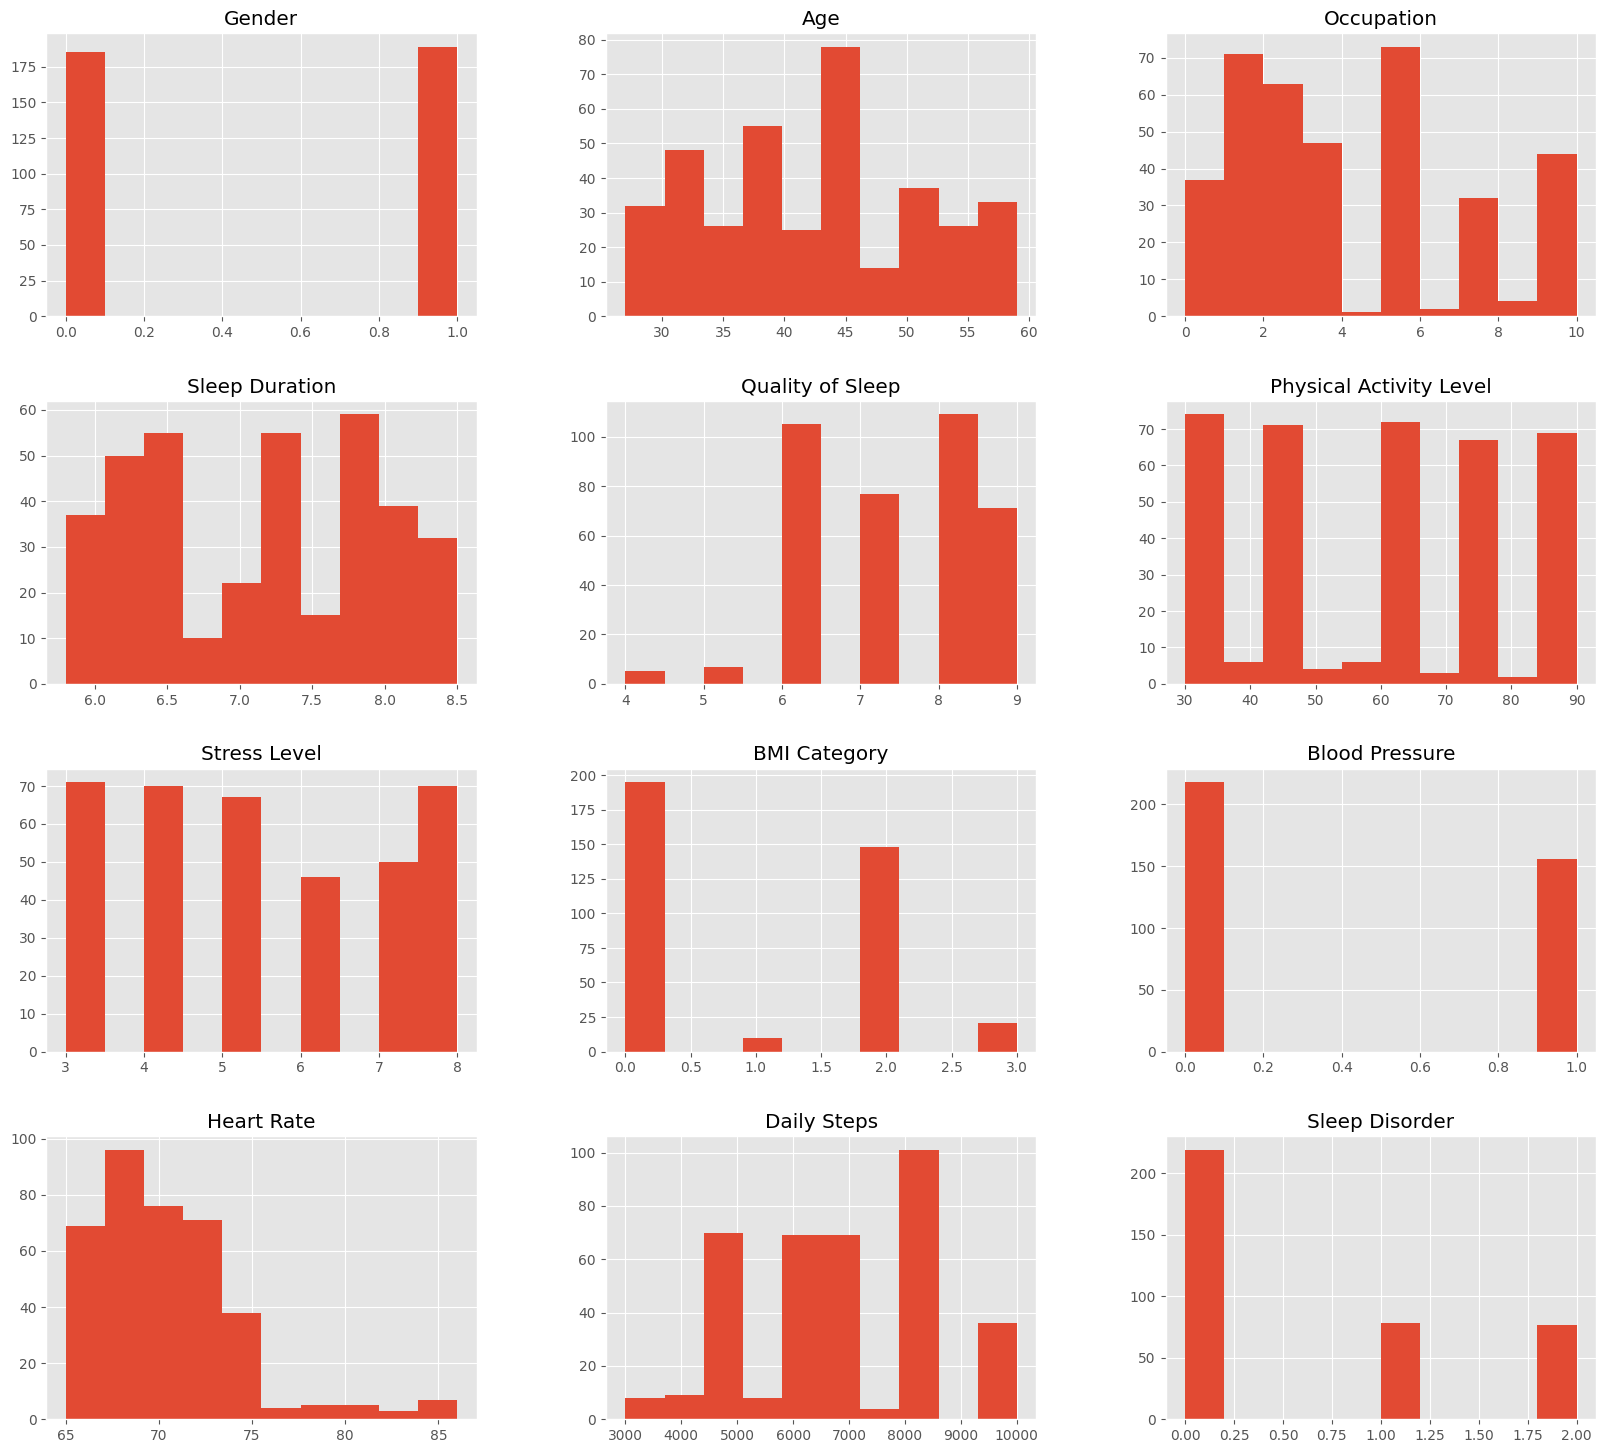

In [105]:
df_tree.hist(figsize=[20,18],bins=10)

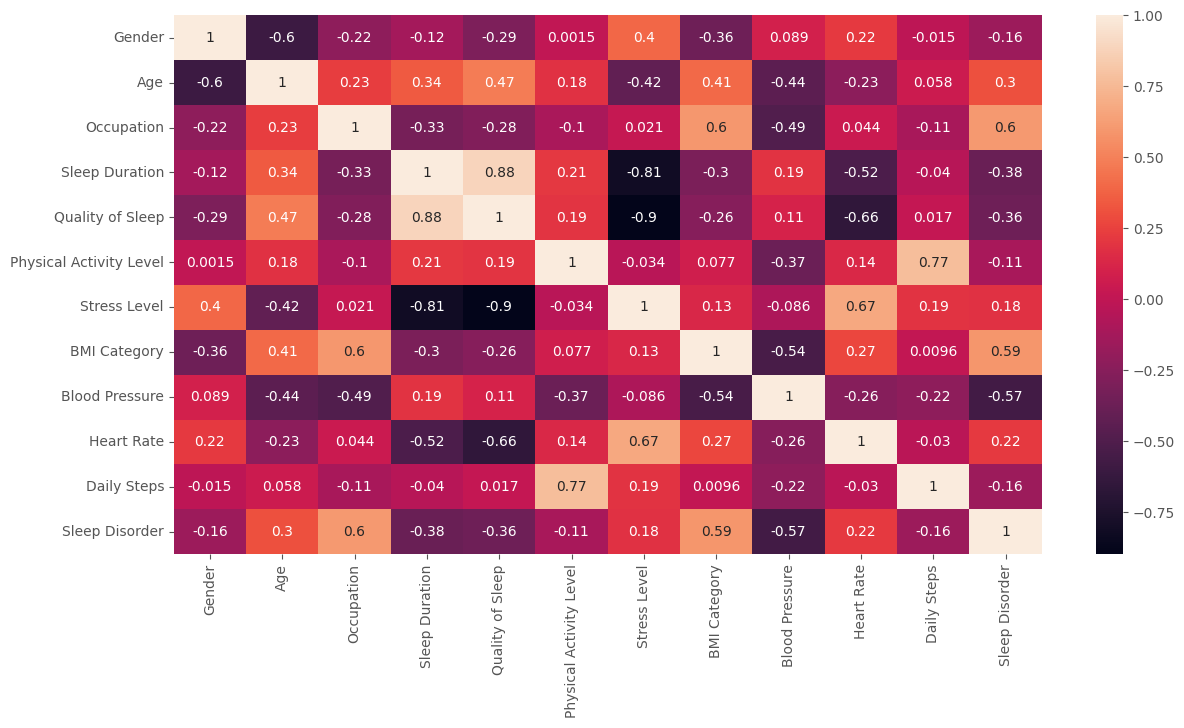

In [106]:
plt.figure(figsize=[14,7])
sns.heatmap(df_tree.select_dtypes('number').corr(),annot=True)
plt.show()

In [107]:
df_nontree=pd.get_dummies(df,columns=string_col,drop_first=False)
df_nontree.head()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Sleep Disorder,Gender_Female,Gender_Male,...,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Obese,BMI Category_Overweight,BMI Category_Under Weight,Blood Pressure_Abnormal,Blood Pressure_Normal
0,27,6.1,6,42,6,77,4200,0,False,True,...,False,False,True,False,False,False,True,False,False,True
1,28,6.2,6,60,8,75,10000,0,False,True,...,False,False,False,False,True,False,False,False,False,True
2,28,6.2,6,60,8,75,10000,0,False,True,...,False,False,False,False,True,False,False,False,False,True
3,28,5.9,4,30,8,85,3000,1,False,True,...,False,False,False,False,False,True,False,False,True,False
4,28,5.9,4,30,8,85,3000,1,False,True,...,False,False,False,False,False,True,False,False,True,False


In [108]:
target="Sleep Disorder"
y=df_nontree[target].values
df_nontree.drop("Sleep Disorder",axis=1,inplace=True)
df_nontree=pd.concat([df_nontree,df[target]],axis=1)
df_nontree.head()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Gender_Female,Gender_Male,Occupation_Accountant,...,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Obese,BMI Category_Overweight,BMI Category_Under Weight,Blood Pressure_Abnormal,Blood Pressure_Normal,Sleep Disorder
0,27,6.1,6,42,6,77,4200,False,True,False,...,False,True,False,False,False,True,False,False,True,0
1,28,6.2,6,60,8,75,10000,False,True,False,...,False,False,False,True,False,False,False,False,True,0
2,28,6.2,6,60,8,75,10000,False,True,False,...,False,False,False,True,False,False,False,False,True,0
3,28,5.9,4,30,8,85,3000,False,True,False,...,False,False,False,False,True,False,False,True,False,1
4,28,5.9,4,30,8,85,3000,False,True,False,...,False,False,False,False,True,False,False,True,False,1


In [109]:
feature_col_nontree=df_nontree.columns.to_list()
feature_col_nontree.remove(target)

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.70      1.00      0.82        44
           1       0.00      0.00      0.00        16
           2       0.67      0.53      0.59        15

    accuracy                           0.69        75
   macro avg       0.46      0.51      0.47        75
weighted avg       0.54      0.69      0.60        75

The accuracy for fold 1 : 0.6933333333333334


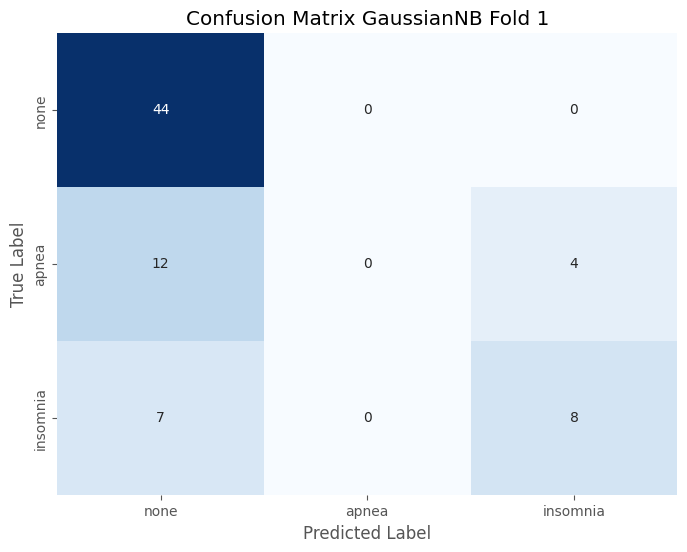

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.94      0.75      0.84        44
           1       0.88      0.94      0.91        16
           2       0.57      0.87      0.68        15

    accuracy                           0.81        75
   macro avg       0.80      0.85      0.81        75
weighted avg       0.85      0.81      0.82        75

The accuracy for fold 2 : 0.8133333333333334


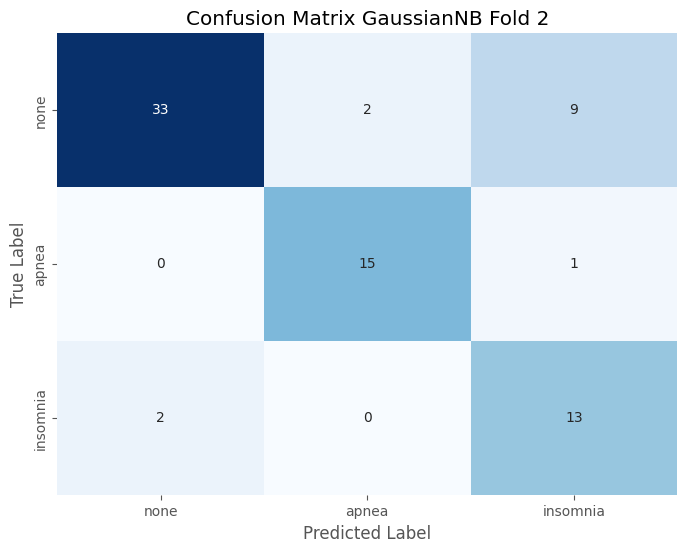

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        44
           1       0.94      1.00      0.97        15
           2       1.00      1.00      1.00        16

    accuracy                           0.99        75
   macro avg       0.98      0.99      0.99        75
weighted avg       0.99      0.99      0.99        75

The accuracy for fold 3 : 0.9866666666666667


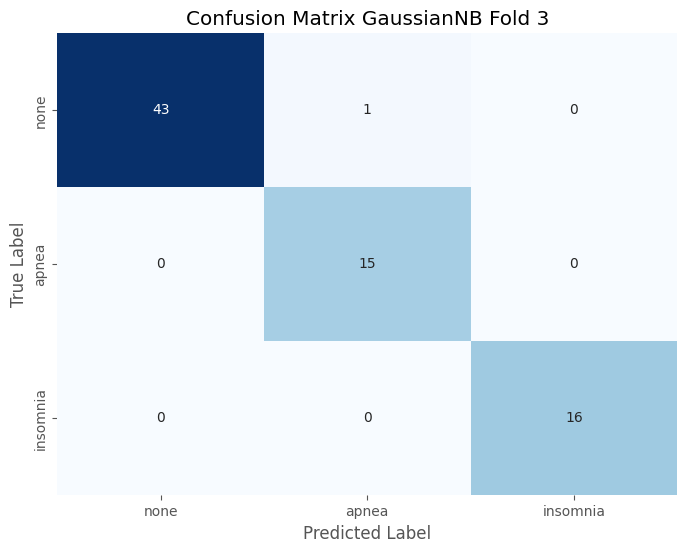

The fold is : 3 : 
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        44
           1       1.00      1.00      1.00        15
           2       0.94      1.00      0.97        16

    accuracy                           0.99        75
   macro avg       0.98      0.99      0.99        75
weighted avg       0.99      0.99      0.99        75

The accuracy for fold 4 : 0.9866666666666667


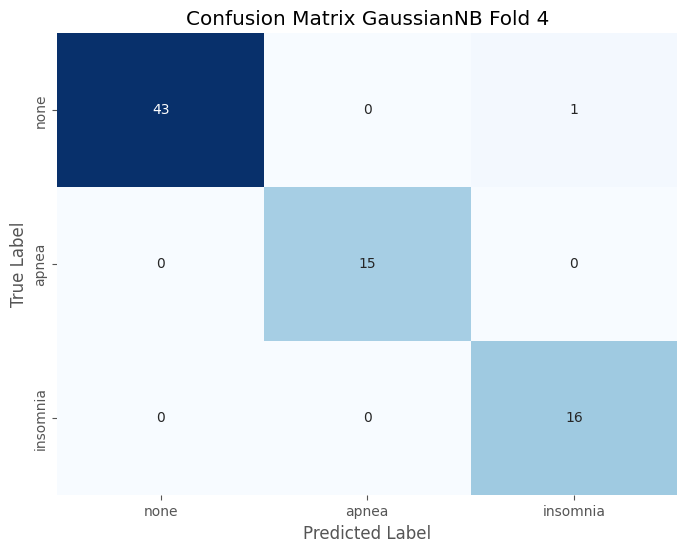

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.82      0.72      0.77        43
           1       0.57      1.00      0.73        16
           2       0.62      0.33      0.43        15

    accuracy                           0.70        74
   macro avg       0.67      0.68      0.64        74
weighted avg       0.72      0.70      0.69        74

The accuracy for fold 5 : 0.7027027027027027


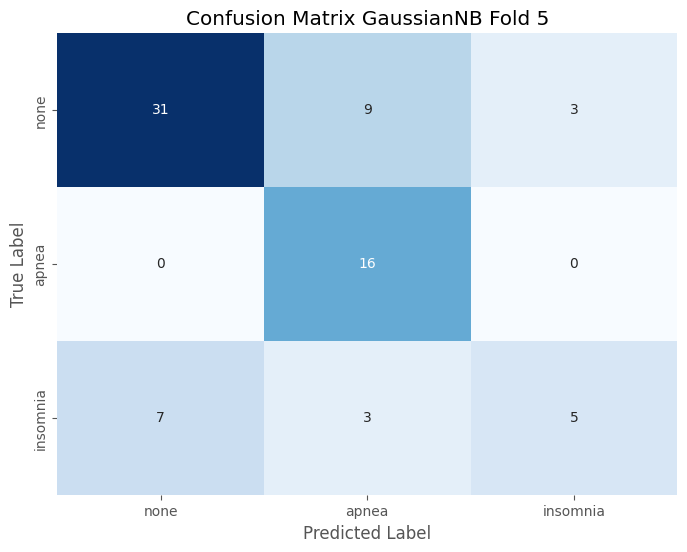

Mean Accuracy: 83.65405405405406%
Max  Accuracy: 98.66666666666667%


In [110]:
acc_Gauss = []
kf = model_selection.StratifiedKFold(n_splits=5, )

for fold, (trn_, val_) in enumerate(kf.split(X=df_nontree, y=df_nontree[target])):
    X_train = df_nontree.loc[trn_, feature_col_nontree]
    y_train = df_nontree.loc[trn_, target]
    
    X_valid = df_nontree.loc[val_, feature_col_nontree]
    y_valid = df_nontree.loc[val_, target]
    
    # Scale features
    # ro_scaler = MinMaxScaler()
    # X_train = ro_scaler.fit_transform(X_train)
    # X_valid = ro_scaler.transform(X_valid)
    
    # Initialize and fit the Gaussian Naive Bayes model
    clf = GaussianNB()
    clf.fit(X_train, y_train)
    
    # Make predictions
    y_pred = clf.predict(X_valid)
    
    # Output results
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid, y_pred))
    
    # Calculate accuracy
    conf = confusion_matrix(y_valid, y_pred)
    acc = accuracy_score(y_valid, y_pred)
    acc_Gauss.append(acc)
    print(f"The accuracy for fold {fold + 1} : {acc}")
    
    # Plot confusion matrix using seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix GaussianNB Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_Gauss=np.mean(acc_Gauss)
print(f"Mean Accuracy: {np.mean(acc_Gauss)*100}%")
print(f"Max  Accuracy: {np.max(acc_Gauss)*100}%")

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.89      0.93      0.91        44
           1       0.85      0.69      0.76        16
           2       0.81      0.87      0.84        15

    accuracy                           0.87        75
   macro avg       0.85      0.83      0.84        75
weighted avg       0.87      0.87      0.86        75

The accuracy for 1 : 0.8666666666666667


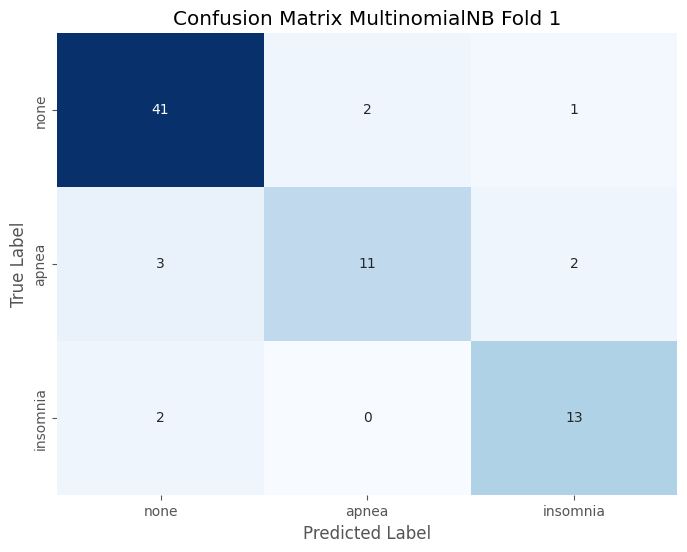

The fold is : 1 : 
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        44
           1       0.83      0.94      0.88        16
           2       0.87      0.87      0.87        15

    accuracy                           0.93        75
   macro avg       0.90      0.92      0.91        75
weighted avg       0.94      0.93      0.93        75

The accuracy for 2 : 0.9333333333333333


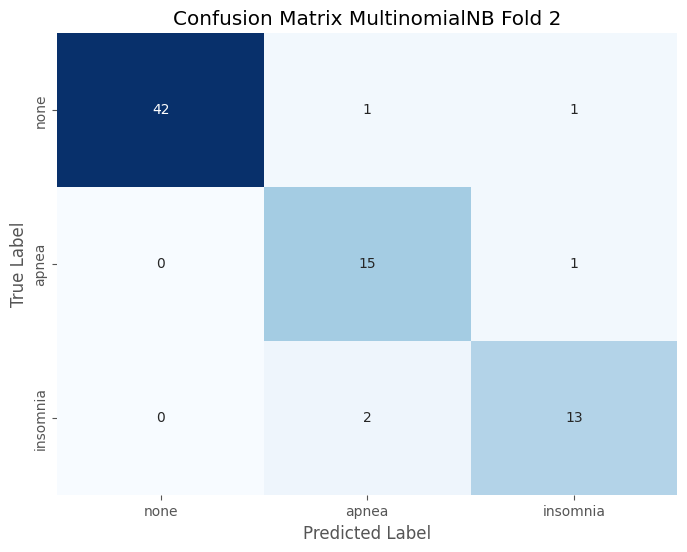

The fold is : 2 : 
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        44
           1       0.93      0.87      0.90        15
           2       0.83      0.94      0.88        16

    accuracy                           0.92        75
   macro avg       0.91      0.91      0.91        75
weighted avg       0.92      0.92      0.92        75

The accuracy for 3 : 0.92


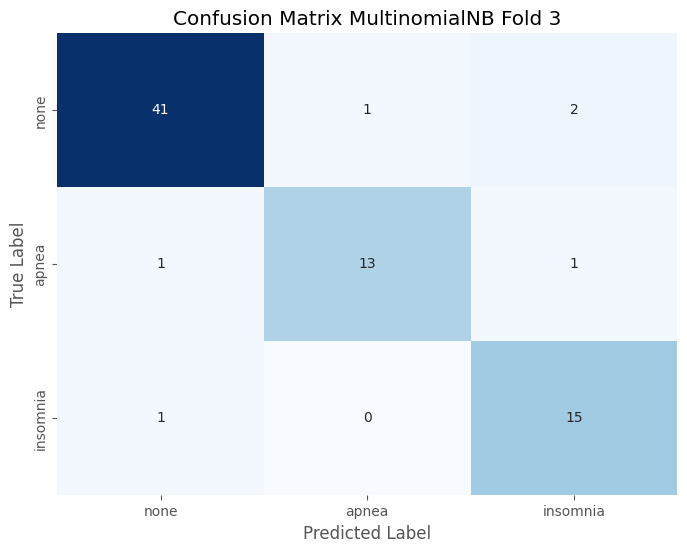

The fold is : 3 : 
              precision    recall  f1-score   support

           0       0.95      0.91      0.93        44
           1       0.76      0.87      0.81        15
           2       0.88      0.88      0.88        16

    accuracy                           0.89        75
   macro avg       0.86      0.88      0.87        75
weighted avg       0.90      0.89      0.89        75

The accuracy for 4 : 0.8933333333333333


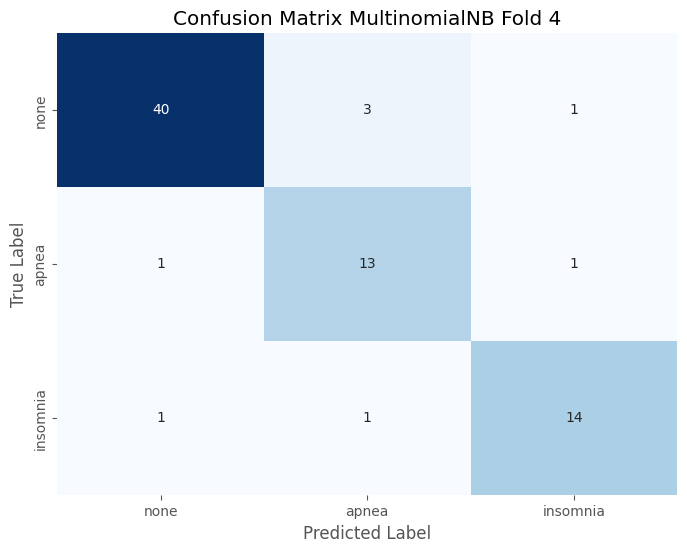

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.89      0.93      0.91        43
           1       0.86      0.75      0.80        16
           2       0.80      0.80      0.80        15

    accuracy                           0.86        74
   macro avg       0.85      0.83      0.84        74
weighted avg       0.86      0.86      0.86        74

The accuracy for 5 : 0.8648648648648649


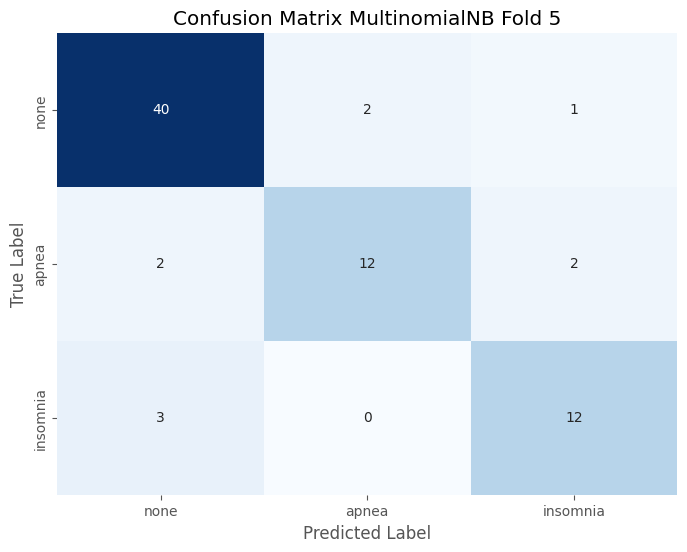

Mean Accuracy: 89.56396396396397%
Max Accuracy: 93.33333333333333%


In [111]:
acc_MulGauss = []
kf = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

for fold, (trn_, val_) in enumerate(kf.split(X=df_nontree, y=df_nontree[target])):
    X_train = df_nontree.loc[trn_, feature_col_nontree]
    y_train = df_nontree.loc[trn_, target]
    
    X_valid = df_nontree.loc[val_, feature_col_nontree]
    y_valid = df_nontree.loc[val_, target]
    
    # Scale features
    ro_scaler = MinMaxScaler()
    X_train = ro_scaler.fit_transform(X_train)
    X_valid = ro_scaler.transform(X_valid)
    
    # Initialize and fit the Multinomial Gaussian Naive Bayes model
    clf = MultinomialNB()
    clf.fit(X_train, y_train)
    
    # Make predictions
    y_pred = clf.predict(X_valid)
    
    # Output results
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid, y_pred))
    
    # Calculate accuracy
    conf = confusion_matrix(y_valid, y_pred)
    acc = accuracy_score(y_valid, y_pred)
    acc_MulGauss.append(acc)
    print(f"The accuracy for {fold+1} : {acc}")
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix MultinomialNB Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_mulgauss=np.mean(acc_MulGauss)
print(f"Mean Accuracy: {np.mean(acc_MulGauss)*100}%")
print(f"Max Accuracy: {np.max(acc_MulGauss)*100}%")

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.71      1.00      0.83        44
           1       0.00      0.00      0.00        16
           2       0.62      0.53      0.57        15

    accuracy                           0.69        75
   macro avg       0.44      0.51      0.47        75
weighted avg       0.54      0.69      0.60        75

The accuracy for 1 : 0.6933333333333334


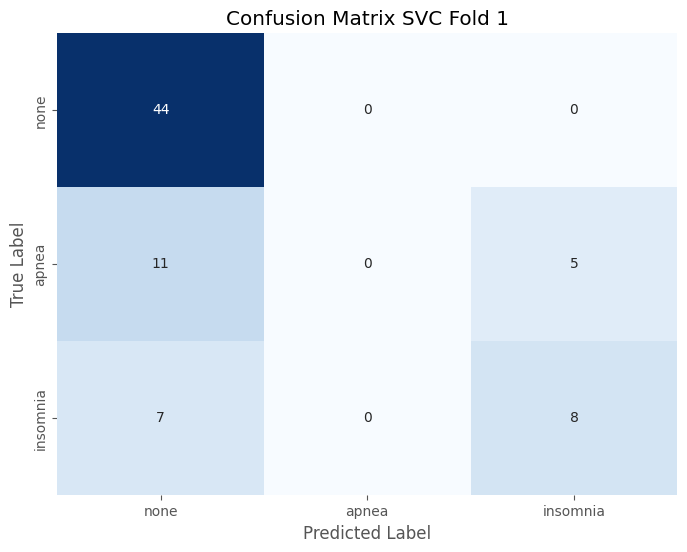

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.95      0.91      0.93        44
           1       0.87      0.81      0.84        16
           2       0.72      0.87      0.79        15

    accuracy                           0.88        75
   macro avg       0.85      0.86      0.85        75
weighted avg       0.89      0.88      0.88        75

The accuracy for 2 : 0.88


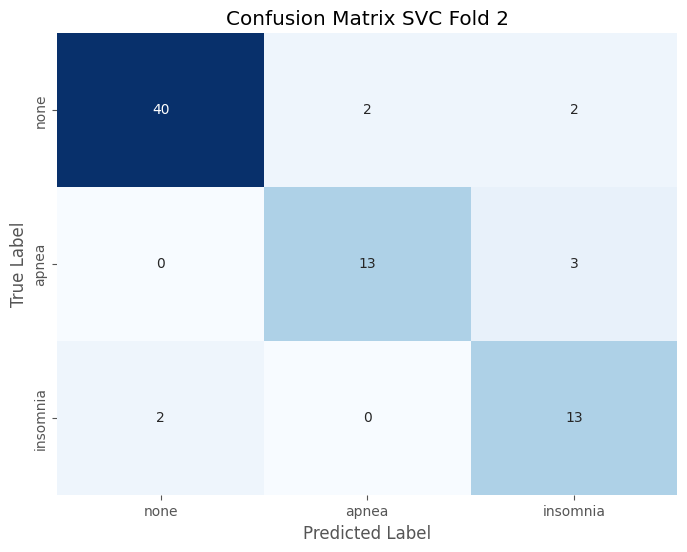

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        44
           1       0.94      1.00      0.97        15
           2       1.00      1.00      1.00        16

    accuracy                           0.99        75
   macro avg       0.98      0.99      0.99        75
weighted avg       0.99      0.99      0.99        75

The accuracy for 3 : 0.9866666666666667


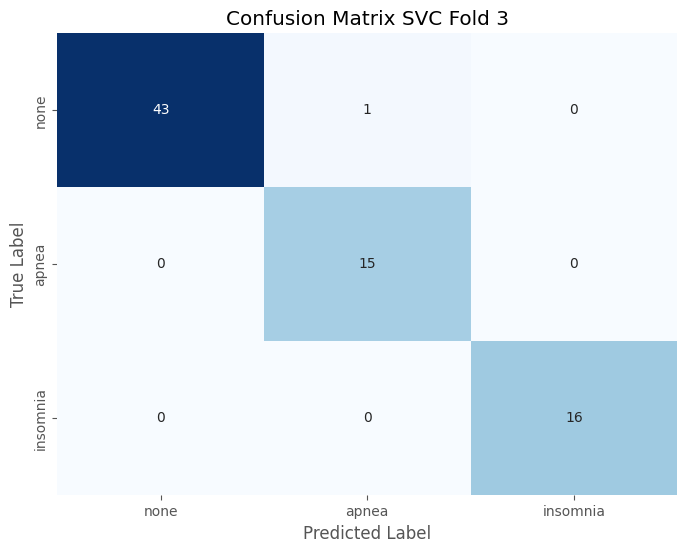

The fold is : 3 : 
              precision    recall  f1-score   support

           0       1.00      0.61      0.76        44
           1       1.00      1.00      1.00        15
           2       0.48      1.00      0.65        16

    accuracy                           0.77        75
   macro avg       0.83      0.87      0.80        75
weighted avg       0.89      0.77      0.79        75

The accuracy for 4 : 0.7733333333333333


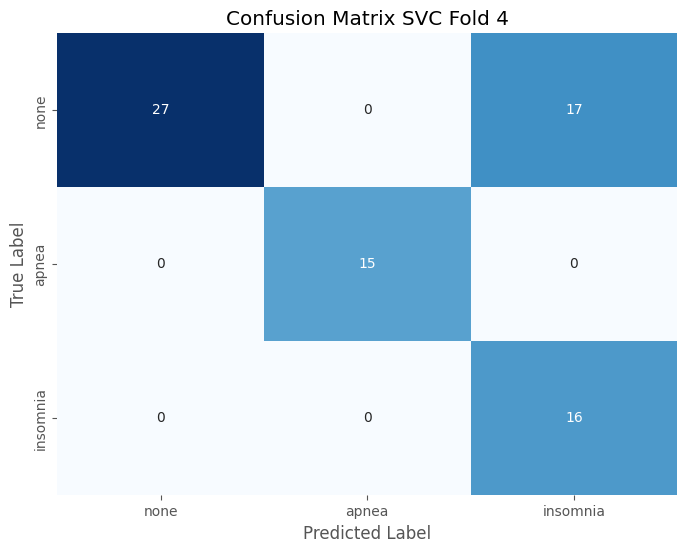

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.97      0.81      0.89        43
           1       0.67      1.00      0.80        16
           2       0.79      0.73      0.76        15

    accuracy                           0.84        74
   macro avg       0.81      0.85      0.81        74
weighted avg       0.87      0.84      0.84        74

The accuracy for 5 : 0.8378378378378378


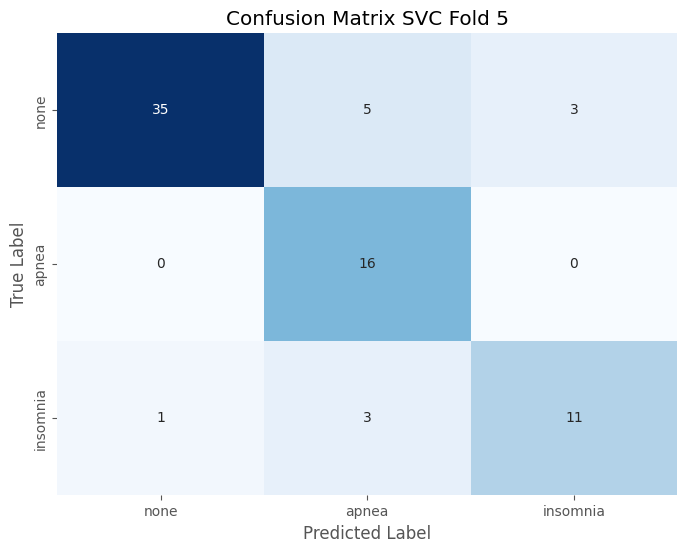

Mean Accuracy: 83.42342342342344%
Max  Accuracy: 98.66666666666667%


In [112]:
acc_svm=[]
kf=model_selection.StratifiedKFold(n_splits=5)
for fold , (trn_,val_) in enumerate(kf.split(X=df_nontree,y=df_nontree[target])):
    
    X_train=df_nontree.loc[trn_,feature_col_nontree]
    y_train=df_nontree.loc[trn_,target]
    
    X_valid=df_nontree.loc[val_,feature_col_nontree]
    y_valid=df_nontree.loc[val_,target]
    
    ro_scaler=MinMaxScaler()
    X_train=ro_scaler.fit_transform(X_train)
    X_valid=ro_scaler.transform(X_valid)
    
    clf=SVC(kernel="linear")
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_valid)
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid,y_pred))

    conf = confusion_matrix(y_valid, y_pred)
    acc=accuracy_score(y_valid,y_pred)
    acc_svm.append(acc)
    print(f"The accuracy for {fold+1} : {acc}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix SVC Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()
    
acc_mean_SVM=np.mean(acc_svm)
print(f"Mean Accuracy: {np.mean(acc_svm)*100}%")
print(f"Max  Accuracy: {np.max(acc_svm)*100}%")

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        44
           1       0.67      0.25      0.36        16
           2       0.67      0.53      0.59        15

    accuracy                           0.75        75
   macro avg       0.70      0.59      0.61        75
weighted avg       0.73      0.75      0.71        75

The accuracy KNN 1 : 0.7466666666666667


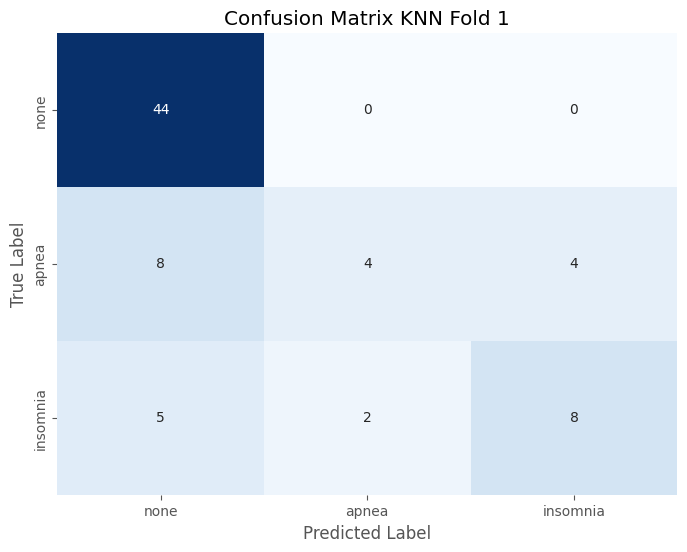

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        44
           1       1.00      0.81      0.90        16
           2       0.72      0.87      0.79        15

    accuracy                           0.88        75
   macro avg       0.88      0.86      0.86        75
weighted avg       0.89      0.88      0.88        75

The accuracy KNN 2 : 0.88


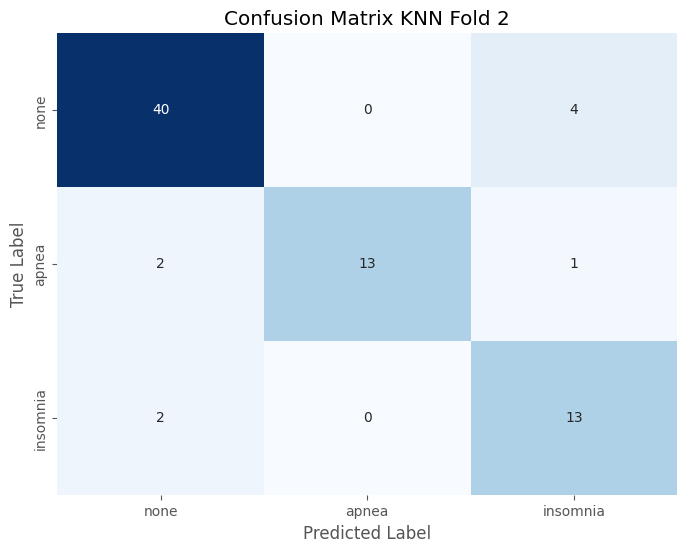

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        44
           1       0.83      1.00      0.91        15
           2       1.00      1.00      1.00        16

    accuracy                           0.96        75
   macro avg       0.94      0.98      0.96        75
weighted avg       0.97      0.96      0.96        75

The accuracy KNN 3 : 0.96


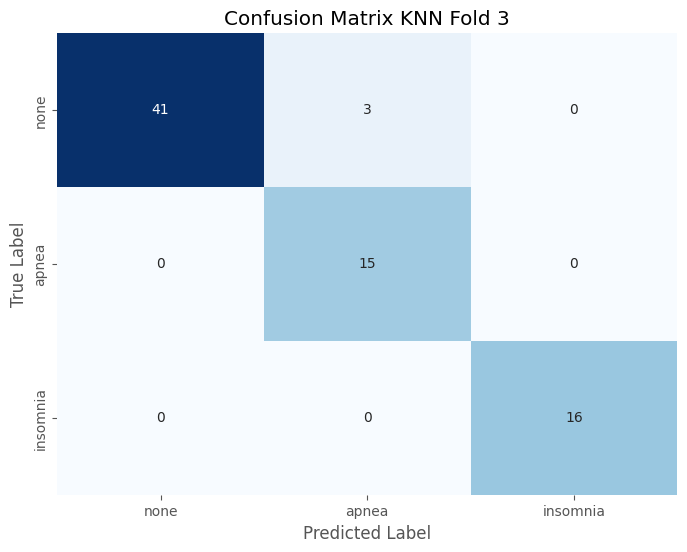

The fold is : 3 : 
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        44
           1       1.00      1.00      1.00        15
           2       0.84      1.00      0.91        16

    accuracy                           0.96        75
   macro avg       0.95      0.98      0.96        75
weighted avg       0.97      0.96      0.96        75

The accuracy KNN 4 : 0.96


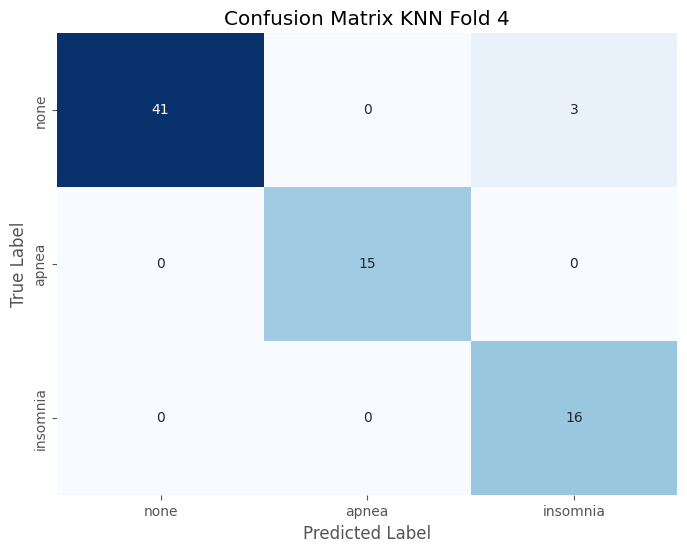

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.97      0.77      0.86        43
           1       0.67      1.00      0.80        16
           2       0.81      0.87      0.84        15

    accuracy                           0.84        74
   macro avg       0.82      0.88      0.83        74
weighted avg       0.87      0.84      0.84        74

The accuracy KNN 5 : 0.8378378378378378


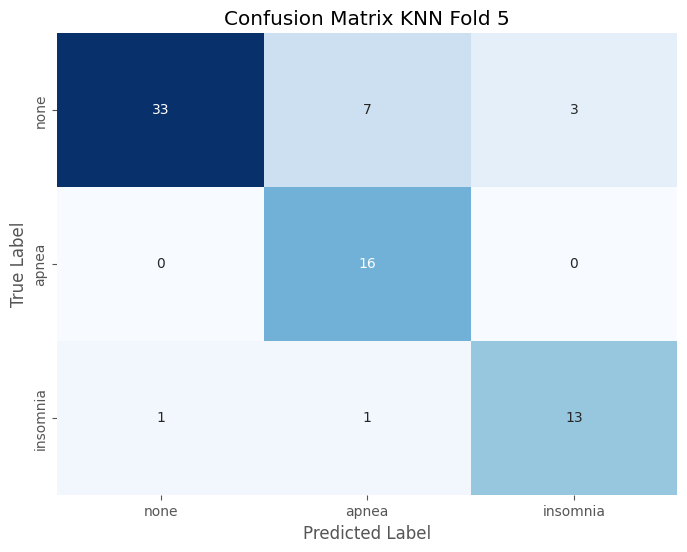

Mean Accuracy: 87.6900900900901%
Mean Accuracy: 96.0%


In [113]:
acc_knn=[]
kf=model_selection.StratifiedKFold(n_splits=5)
for fold , (trn_,val_) in enumerate(kf.split(X=df_nontree,y=df_nontree[target])):
    
    X_train=df_nontree.loc[trn_,feature_col_nontree]
    y_train=df_nontree.loc[trn_,target]
    
    X_valid=df_nontree.loc[val_,feature_col_nontree]
    y_valid=df_nontree.loc[val_,target]
    
    ro_scaler=MinMaxScaler()
    X_train=ro_scaler.fit_transform(X_train)
    X_valid=ro_scaler.transform(X_valid)
    
    clf=KNeighborsClassifier(n_neighbors=32)
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_valid)
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid,y_pred))

    conf = confusion_matrix(y_valid, y_pred)
    acc=accuracy_score(y_valid,y_pred)
    acc_knn.append(acc)
    print(f"The accuracy KNN {fold+1} : {acc}")
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix KNN Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_KNN=np.mean(acc_knn)
print(f"Mean Accuracy: {np.mean(acc_knn)*100}%")
print(f"Mean Accuracy: {np.max(acc_knn)*100}%")

In [114]:
feature_col_tree=df_tree.columns.to_list()
feature_col_tree.remove(target)

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.62      1.00      0.77        44
           1       0.00      0.00      0.00        16
           2       1.00      0.27      0.42        15

    accuracy                           0.64        75
   macro avg       0.54      0.42      0.40        75
weighted avg       0.56      0.64      0.53        75

The accuracy for 1 : 0.64


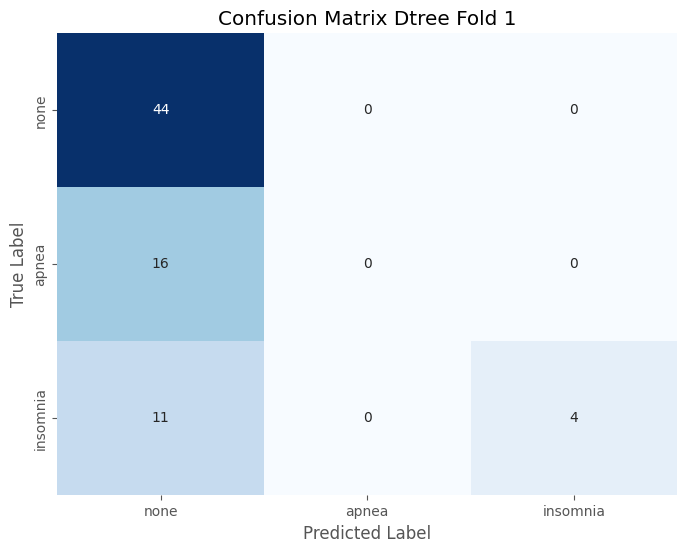

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.84      0.59      0.69        44
           1       0.67      0.62      0.65        16
           2       0.45      0.87      0.59        15

    accuracy                           0.65        75
   macro avg       0.65      0.69      0.64        75
weighted avg       0.72      0.65      0.66        75

The accuracy for 2 : 0.6533333333333333


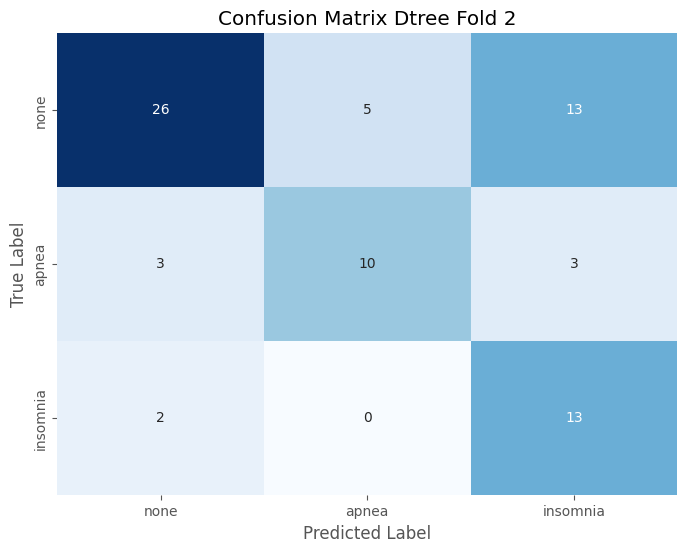

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        44
           1       0.83      1.00      0.91        15
           2       1.00      1.00      1.00        16

    accuracy                           0.96        75
   macro avg       0.94      0.98      0.96        75
weighted avg       0.97      0.96      0.96        75

The accuracy for 3 : 0.96


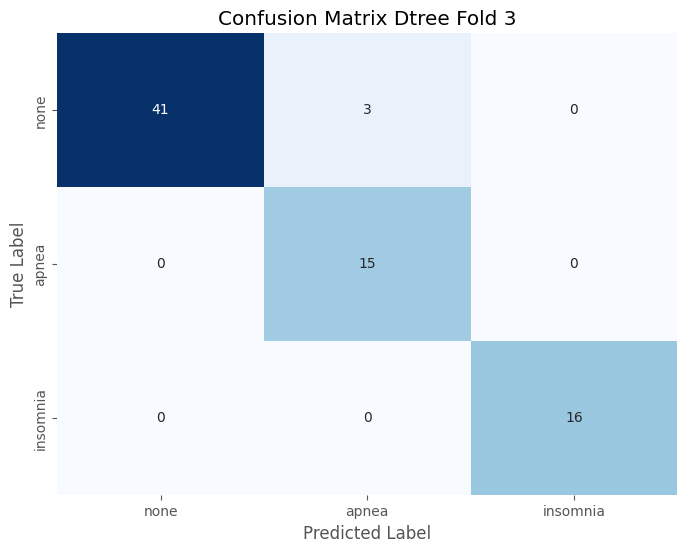

The fold is : 3 : 
              precision    recall  f1-score   support

           0       0.83      0.34      0.48        44
           1       0.92      0.80      0.86        15
           2       0.34      0.94      0.50        16

    accuracy                           0.56        75
   macro avg       0.70      0.69      0.61        75
weighted avg       0.75      0.56      0.56        75

The accuracy for 4 : 0.56


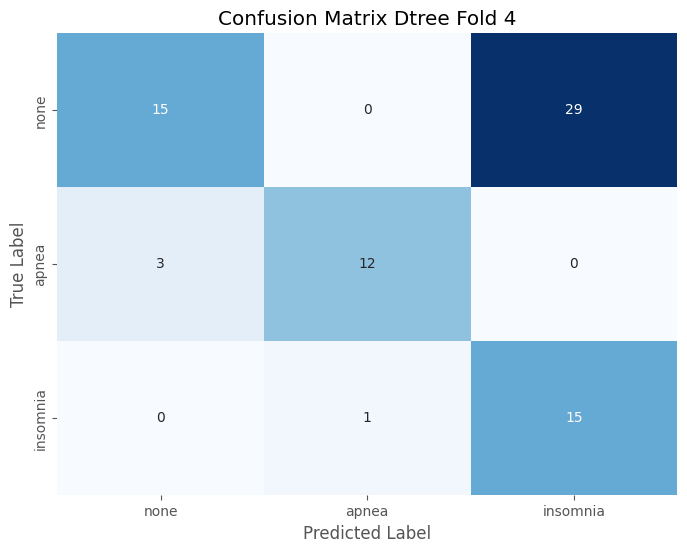

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.83      0.79      0.81        43
           1       0.64      1.00      0.78        16
           2       0.62      0.33      0.43        15

    accuracy                           0.74        74
   macro avg       0.70      0.71      0.67        74
weighted avg       0.75      0.74      0.73        74

The accuracy for 5 : 0.7432432432432432


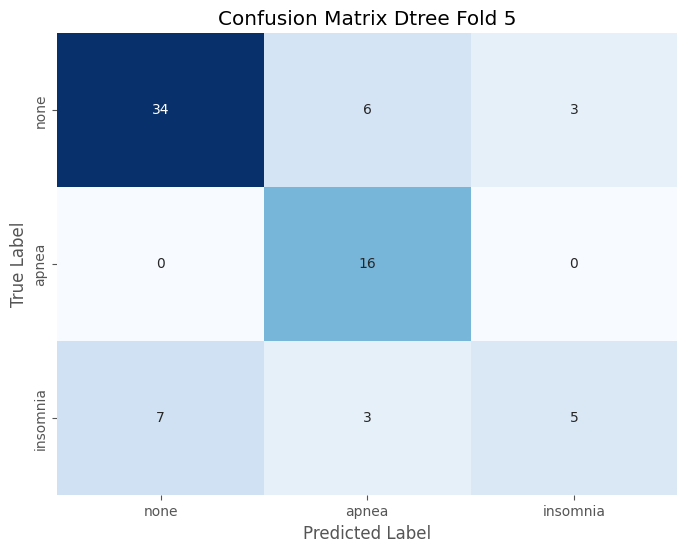

Mean Accuracy: 71.13153153153154%
Max  Accuracy: 96.0%


In [115]:
acc_Dtree=[]
kf=model_selection.StratifiedKFold(n_splits=5)
for fold , (trn_,val_) in enumerate(kf.split(X=df_tree,y=df_tree[target])):
    
    X_train=df_tree.loc[trn_,feature_col_tree]
    y_train=df_tree.loc[trn_,target]
    
    X_valid=df_tree.loc[val_,feature_col_tree]
    y_valid=df_tree.loc[val_,target]
    
    clf=DecisionTreeClassifier(criterion="entropy")
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_valid)
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid,y_pred))

    conf = confusion_matrix(y_valid, y_pred)
    acc=accuracy_score(y_valid,y_pred)
    acc_Dtree.append(acc)
    print(f"The accuracy for {fold+1} : {acc}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix Dtree Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_dtree=np.mean(acc_Dtree)
print(f"Mean Accuracy: {np.mean(acc_Dtree)*100}%")
print(f"Max  Accuracy: {np.max(acc_Dtree)*100}%")

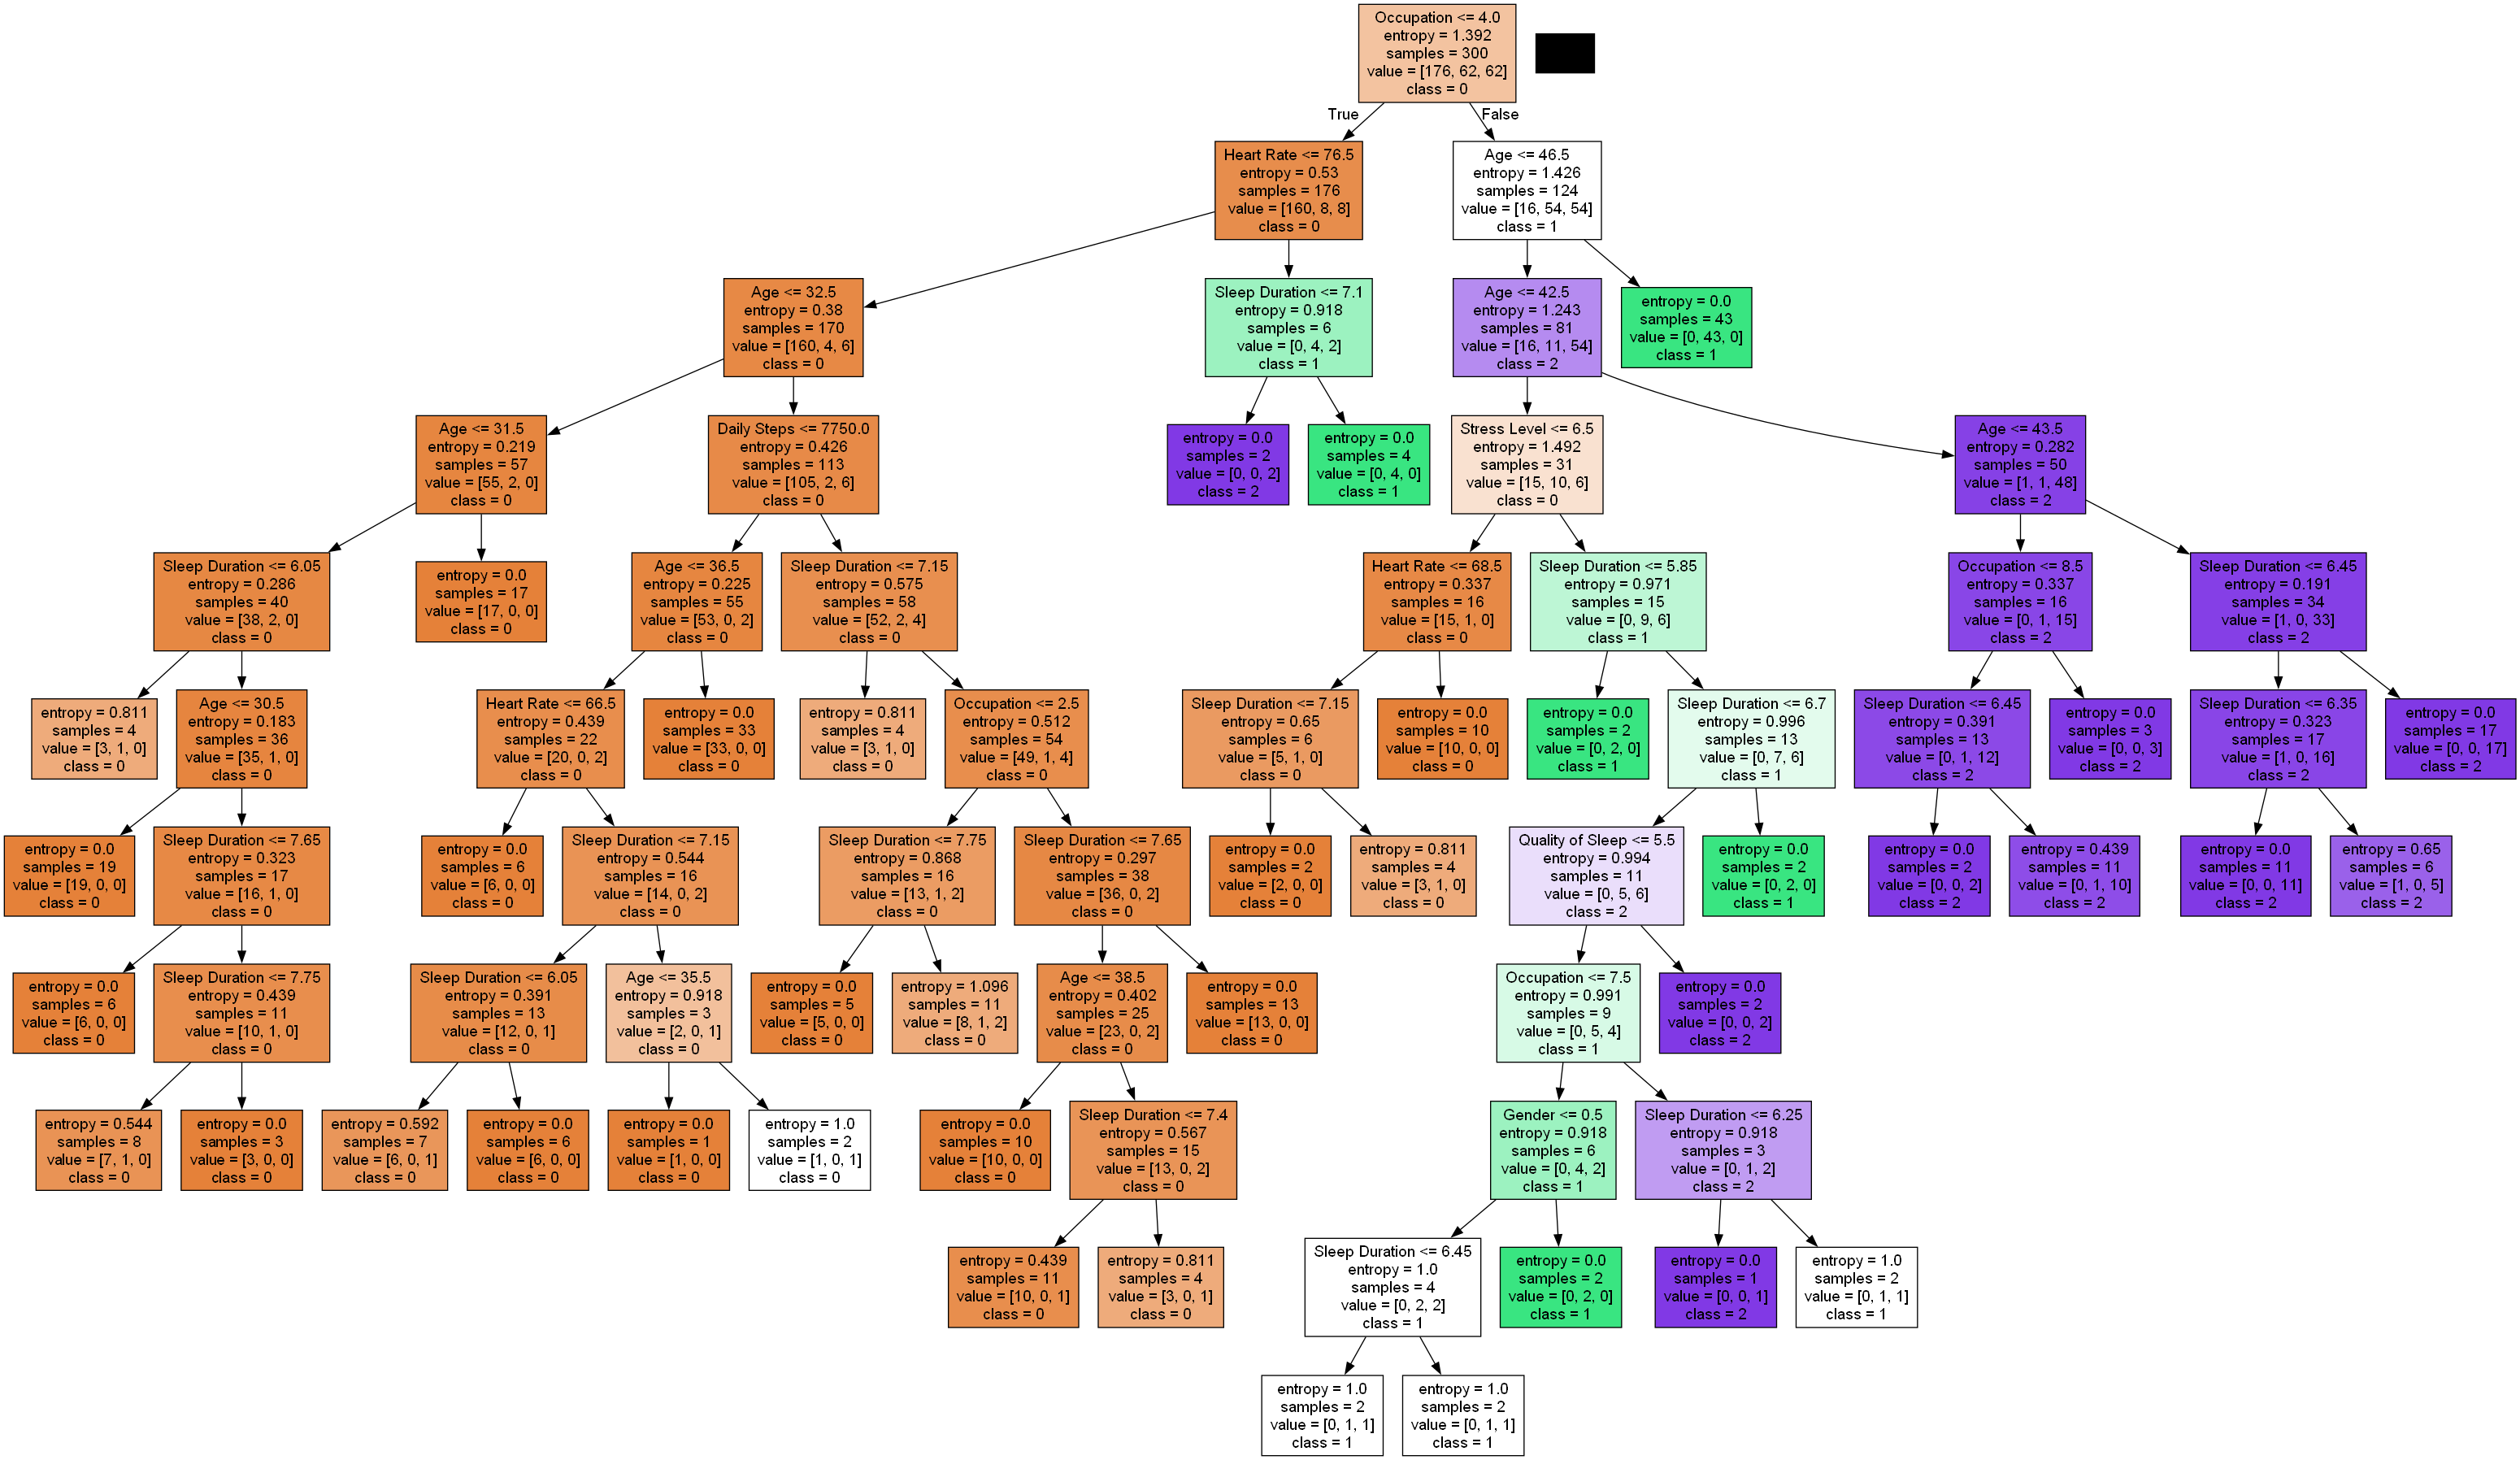

In [116]:
class_labels = df_tree[target].unique().astype(str)
# DOT data
dot_data = tree.export_graphviz(clf, out_file=None, 
                                feature_names=feature_col_tree,  
                                class_names=class_labels,
                                filled=True)

# Draw graph
graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.65      1.00      0.79        44
           1       0.00      0.00      0.00        16
           2       0.71      0.33      0.45        15

    accuracy                           0.65        75
   macro avg       0.45      0.44      0.41        75
weighted avg       0.52      0.65      0.55        75

The accuracy for 1 : 0.6533333333333333


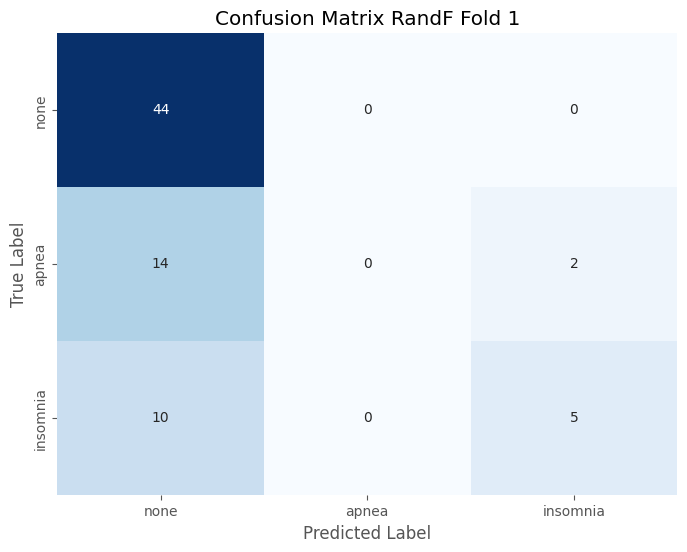

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.85      0.66      0.74        44
           1       0.67      0.62      0.65        16
           2       0.50      0.87      0.63        15

    accuracy                           0.69        75
   macro avg       0.67      0.72      0.67        75
weighted avg       0.74      0.69      0.70        75

The accuracy for 2 : 0.6933333333333334


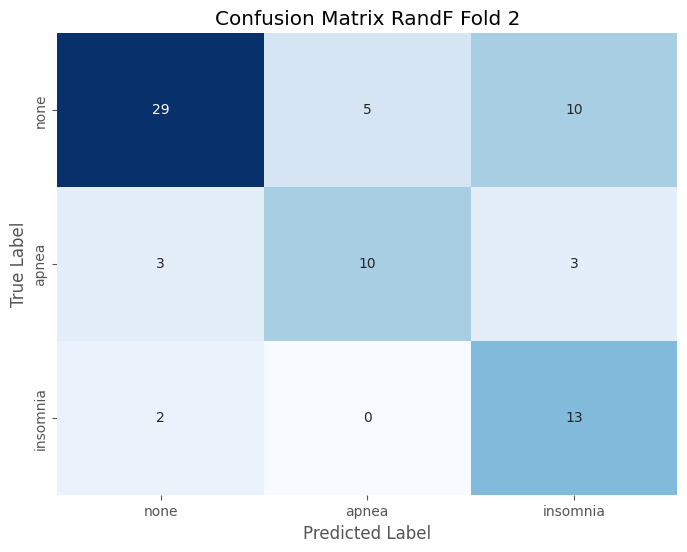

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        44
           1       0.83      1.00      0.91        15
           2       1.00      1.00      1.00        16

    accuracy                           0.96        75
   macro avg       0.94      0.98      0.96        75
weighted avg       0.97      0.96      0.96        75

The accuracy for 3 : 0.96


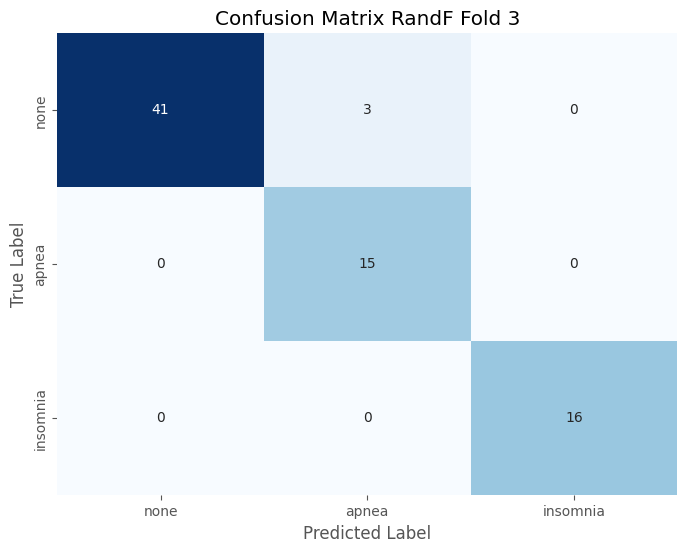

The fold is : 3 : 
              precision    recall  f1-score   support

           0       0.62      0.36      0.46        44
           1       1.00      0.33      0.50        15
           2       0.36      1.00      0.53        16

    accuracy                           0.49        75
   macro avg       0.66      0.57      0.50        75
weighted avg       0.64      0.49      0.48        75

The accuracy for 4 : 0.49333333333333335


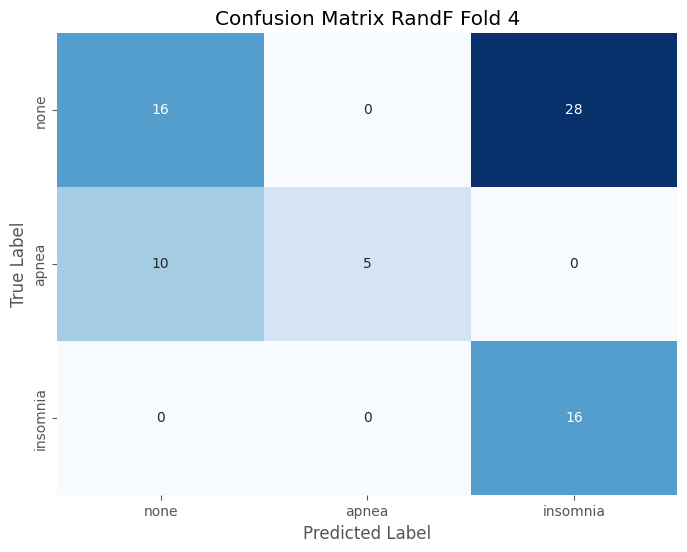

The fold is : 4 : 
              precision    recall  f1-score   support

           0       0.97      0.74      0.84        43
           1       0.59      1.00      0.74        16
           2       0.79      0.73      0.76        15

    accuracy                           0.80        74
   macro avg       0.78      0.83      0.78        74
weighted avg       0.85      0.80      0.80        74

The accuracy for 5 : 0.7972972972972973


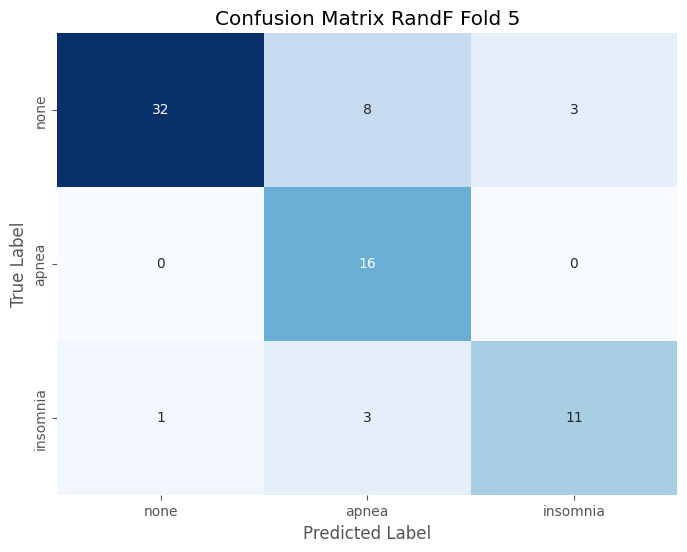

Mean Accuracy: 71.94594594594594%
Max  Accuracy: 96.0%


In [117]:
acc_RandF=[]
kf=model_selection.StratifiedKFold(n_splits=5)
for fold , (trn_,val_) in enumerate(kf.split(X=df_tree,y=df_tree[target])):
    
    X_train=df_tree.loc[trn_,feature_col_tree]
    y_train=df_tree.loc[trn_,target]
    
    X_valid=df_tree.loc[val_,feature_col_tree]
    y_valid=df_tree.loc[val_,target]
    
    clf=RandomForestClassifier(n_estimators=200,criterion="entropy")
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_valid)
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid,y_pred))

    conf = confusion_matrix(y_valid, y_pred)
    acc=accuracy_score(y_valid,y_pred)
    acc_RandF.append(acc)
    print(f"The accuracy for {fold+1} : {acc}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix RandF Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_randf=np.mean(acc_RandF)
print(f"Mean Accuracy: {np.mean(acc_RandF)*100}%")
print(f"Max  Accuracy: {np.max(acc_RandF)*100}%")

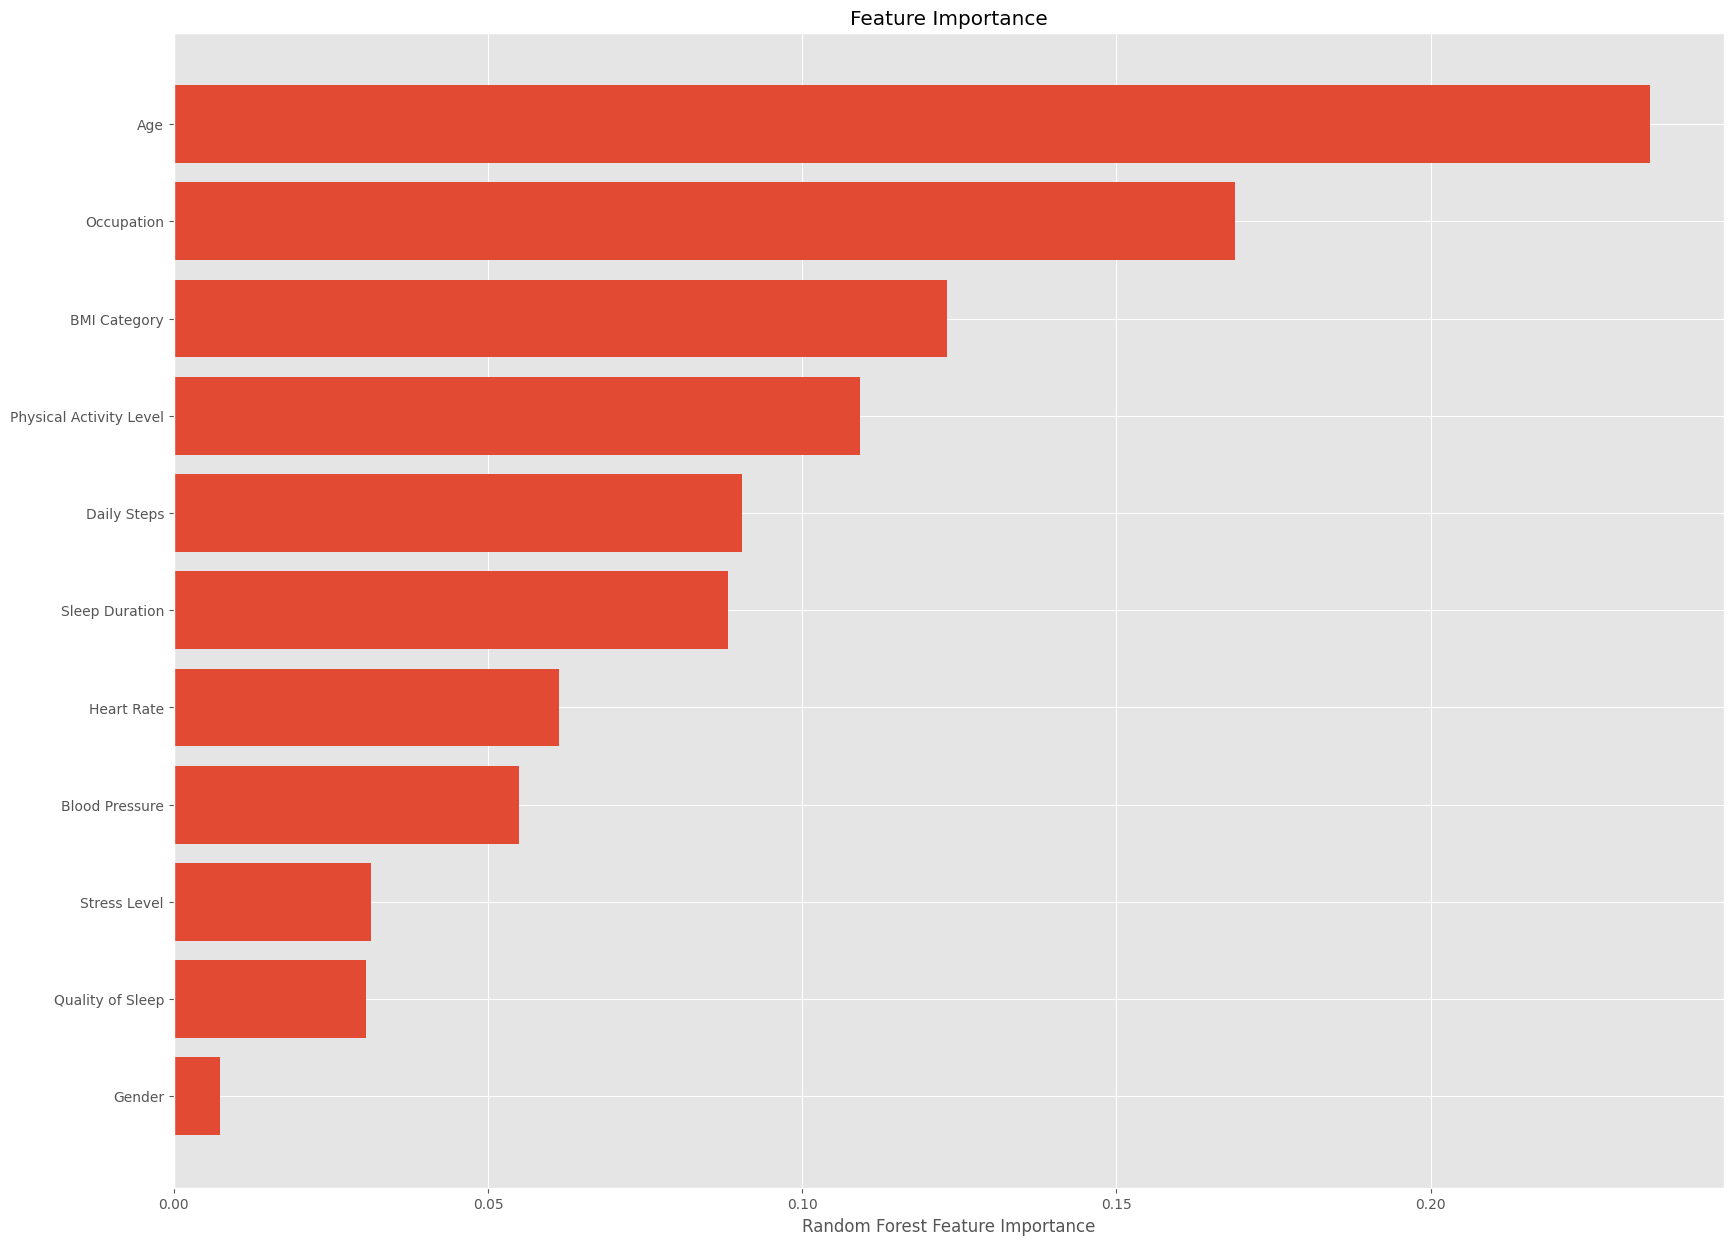

In [118]:
plt.figure(figsize=(20,15))
importance = clf.feature_importances_
idxs = np.argsort(importance)
plt.title("Feature Importance")
plt.barh(range(len(idxs)),importance[idxs],align="center")
plt.yticks(range(len(idxs)),[feature_col_tree[i] for i in idxs])
plt.xlabel("Random Forest Feature Importance")
#plt.tight_layout()
plt.show()

The fold is : 0 : 
              precision    recall  f1-score   support

           0       0.65      1.00      0.79        44
           1       0.00      0.00      0.00        16
           2       0.71      0.33      0.45        15

    accuracy                           0.65        75
   macro avg       0.45      0.44      0.41        75
weighted avg       0.52      0.65      0.55        75

The accuracy for 1 : 0.6533333333333333


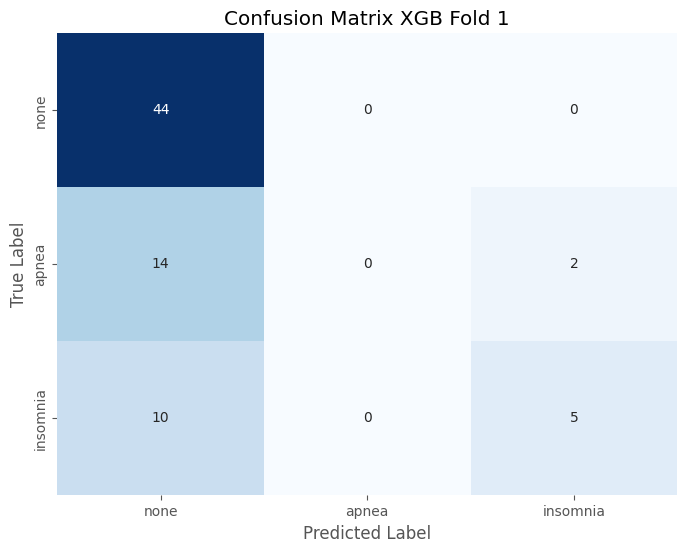

The fold is : 1 : 
              precision    recall  f1-score   support

           0       0.66      0.48      0.55        44
           1       0.46      0.38      0.41        16
           2       0.43      0.87      0.58        15

    accuracy                           0.53        75
   macro avg       0.52      0.57      0.51        75
weighted avg       0.57      0.53      0.53        75

The accuracy for 2 : 0.5333333333333333


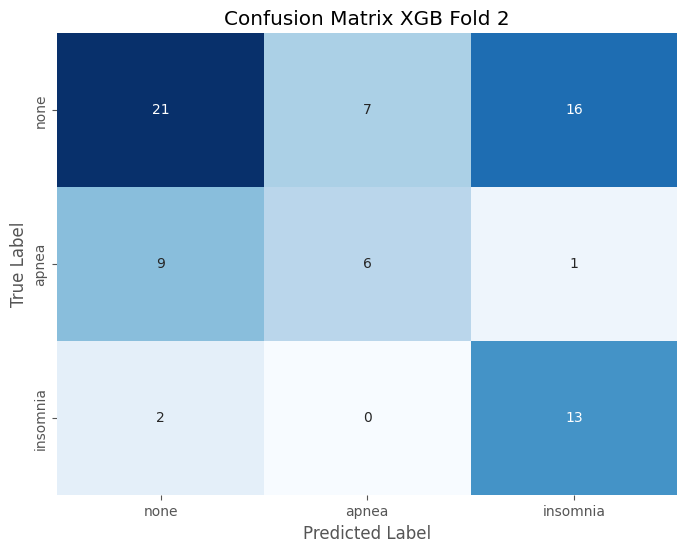

The fold is : 2 : 
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        44
           1       0.79      1.00      0.88        15
           2       1.00      1.00      1.00        16

    accuracy                           0.95        75
   macro avg       0.93      0.97      0.94        75
weighted avg       0.96      0.95      0.95        75

The accuracy for 3 : 0.9466666666666667


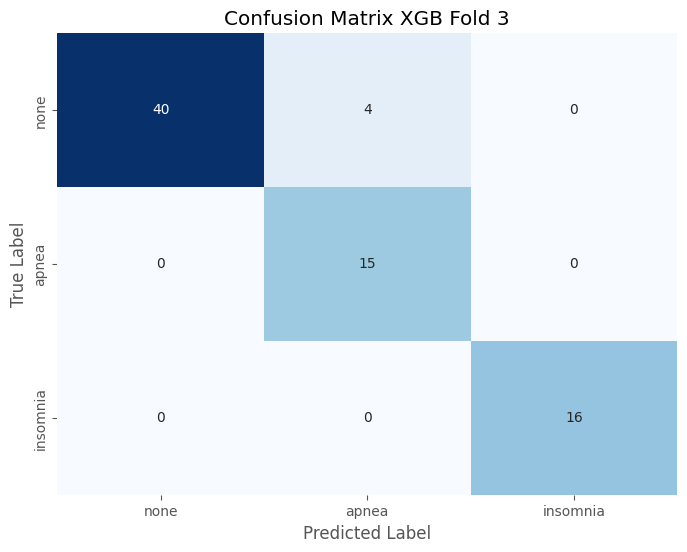

The fold is : 3 : 
              precision    recall  f1-score   support

           0       0.60      0.34      0.43        44
           1       0.50      0.33      0.40        15
           2       0.40      1.00      0.57        16

    accuracy                           0.48        75
   macro avg       0.50      0.56      0.47        75
weighted avg       0.54      0.48      0.46        75

The accuracy for 4 : 0.48


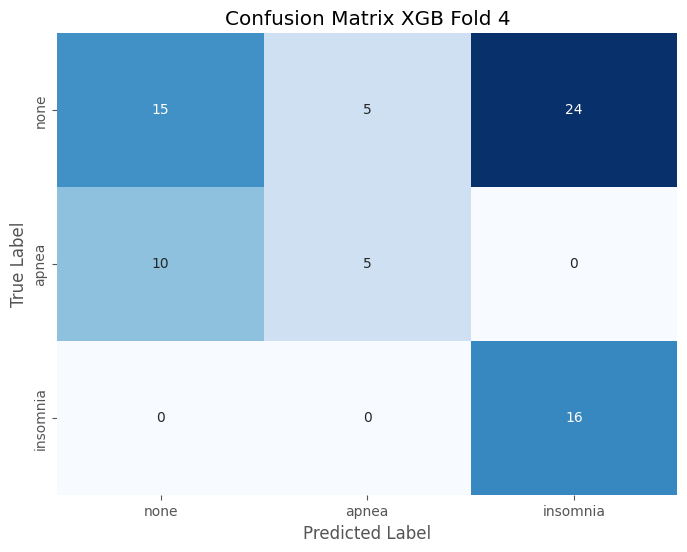

The fold is : 4 : 
              precision    recall  f1-score   support

           0       1.00      0.02      0.05        43
           1       0.25      1.00      0.40        16
           2       0.62      0.33      0.43        15

    accuracy                           0.30        74
   macro avg       0.62      0.45      0.29        74
weighted avg       0.76      0.30      0.20        74

The accuracy for 5 : 0.2972972972972973


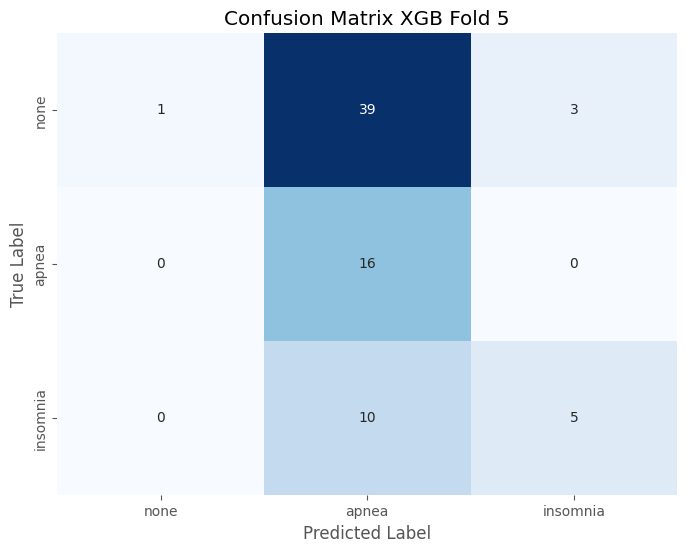

Mean Accuracy: 58.21261261261262%
Max  Accuracy: 94.66666666666667%


In [119]:
acc_XGB=[]
kf=model_selection.StratifiedKFold(n_splits=5)
for fold , (trn_,val_) in enumerate(kf.split(X=df_tree,y=df_tree[target])):
    
    X_train=df_tree.loc[trn_,feature_col_tree]
    y_train=df_tree.loc[trn_,target]
    
    X_valid=df_tree.loc[val_,feature_col_tree]
    y_valid=df_tree.loc[val_,target]
    
    clf=XGBClassifier()
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_valid)
    print(f"The fold is : {fold} : ")
    print(classification_report(y_valid,y_pred))

    conf = confusion_matrix(y_valid,y_pred)
    acc=accuracy_score(y_valid,y_pred)
    acc_XGB.append(acc)
    print(f"The accuracy for {fold+1} : {acc}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['none', 'apnea', 'insomnia'],
                yticklabels=['none', 'apnea', 'insomnia'])
    plt.title(f'Confusion Matrix XGB Fold {fold + 1}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

acc_mean_XGB=np.mean(acc_XGB)
print(f"Mean Accuracy: {np.mean(acc_XGB)*100}%")
print(f"Max  Accuracy: {np.max(acc_XGB)*100}%")

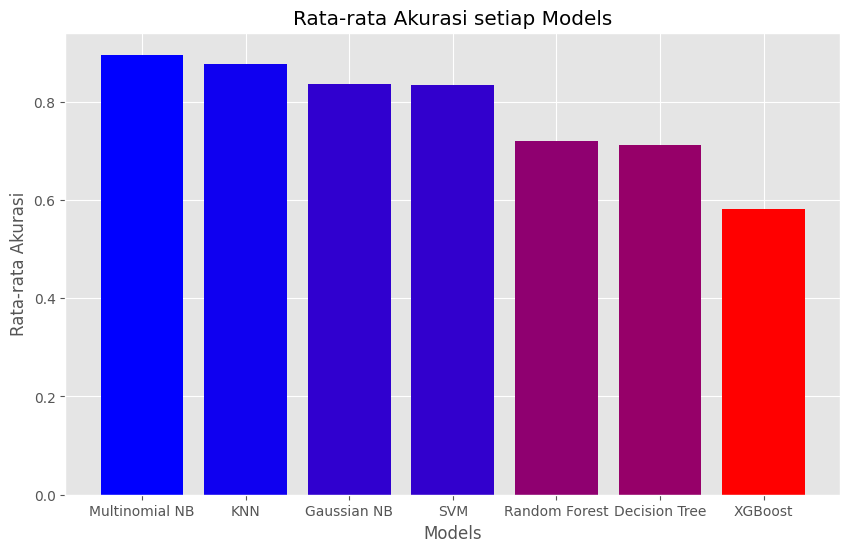

In [120]:
models = ["Gaussian NB", "Multinomial NB", "SVM", "KNN", "Decision Tree", "Random Forest", "XGBoost"]

mean_accuracies = [acc_mean_Gauss, acc_mean_mulgauss, acc_mean_SVM, acc_mean_KNN, acc_mean_dtree, acc_mean_randf, acc_mean_XGB]

models_and_accuracies = sorted(zip(mean_accuracies, models), reverse=True)
sorted_accuracies, sorted_models = zip(*models_and_accuracies)

cmap = LinearSegmentedColormap.from_list("blue_to_red", ["red", "blue"])

norm_accuracies = (np.array(sorted_accuracies) - min(sorted_accuracies)) / (max(sorted_accuracies) - min(sorted_accuracies))
colors = cmap(norm_accuracies)  

plt.figure(figsize=(10, 6))
bars = plt.bar(sorted_models, sorted_accuracies, color=colors)

plt.title('Rata-rata Akurasi setiap Models')
plt.xlabel('Models')
plt.ylabel('Rata-rata Akurasi')

plt.show()

In [121]:
print(f"gaussNB : {acc_mean_Gauss*100}%")
print(f"mulgauss : {acc_mean_mulgauss*100}%")
print(f"SVM : {acc_mean_SVM*100}%")
print(f"KNN : {acc_mean_KNN*100}%")
print(f"Dtree : {acc_mean_dtree*100}%")
print(f"RandomF : {acc_mean_randf*100}%")
print(f"XGB : {acc_mean_XGB*100}%" )

gaussNB : 83.65405405405406%
mulgauss : 89.56396396396397%
SVM : 83.42342342342344%
KNN : 87.6900900900901%
Dtree : 71.13153153153154%
RandomF : 71.94594594594594%
XGB : 58.21261261261262%
